In [104]:
import sys
sys.path.append(r"C:\Users\acostamendoza\projects\distance-project")
from path_setup import setup_project_path
setup_project_path()

import numpy as np
from scipy import io
import matplotlib.pyplot as plt
from src.utils import setup_plot_style, import_vars_from_matlab
from path_setup import setup_project_path
from src.ActivityPipelines import ActivityLoader
from src.DistanceProject import DistanceAnalysis, create_new_result_dir
from src.DistancePlots import plot_repeats, plot_trials, plot_raw_traces, plot_trials_ordered, plot_reliability_distribution, plot_trials_ordered_2, plot_boxplot, plot_RF_vs_modulation
import os
from scipy.stats import f_oneway, ttest_ind
from scipy.ndimage import gaussian_filter1d

colors = setup_plot_style()

%load_ext autoreload
%autoreload 2

data_dir = r'D:/data-distance-coding-project/processed-data'
session = r'250409_SAM033'

session_path = os.path.join(data_dir, session)
results_path = create_new_result_dir(session_path, r'results')
stimulus_path = os.path.join(session_path, r'stimulus')
activity_path = os.path.join(session_path, r'suite2p\plane0')

# check files inside stimulus_path
filelist = [file for file in os.listdir(stimulus_path) if file.endswith(("_stimulus.mat"))]
if len(filelist) == 0:
    # raise error
    raise Exception('No stimulus file found')
elif len(filelist) > 1:
    raise Exception('More than one stimulus file found')
else:
    print('Stimulus file found')

container = io.loadmat(stimulus_path + '/' + str(filelist[0]))

D = ActivityLoader(session_path)

# hardware variables
miniservo_pre_active_time = 1000
miniservo_to_active_time = 2400
miniservo_active_hold = 100
miniservo_to_inactive_time = 2400

# for every cell in D.spikes, smooth using gaussian of sigma 1
D.spikes = np.array([gaussian_filter1d(cell, axis=0, sigma=2) for cell in D.spikes])
# for every cell, z-score the spikes
D.spikes = (D.spikes - np.mean(D.spikes, axis=0)) / np.std(D.spikes, axis=0)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Directory results already exists
Stimulus file found


In [105]:
locals_dict = import_vars_from_matlab(container, 'stim')

time = locals_dict['time']
stepper_pos = locals_dict['stepper_pos']
servo_id = locals_dict['servo_id']
mini_servo_active = locals_dict['mini_servo_active']
trial_sequence = locals_dict['trial_sequence']
history_sequence = locals_dict['history_sequence']
trial_start_time = locals_dict['trial_start_time']
trial_end_time = locals_dict['trial_end_time']
monocular_sequence = locals_dict['monocular_sequence']

if len(monocular_sequence) == 0:
    monocular_sequence = np.ones_like(trial_sequence)

# Filter out frames that occur after the last trial ends


In [22]:
def get_trial_frames(repeat):
    # This function returns a boolean mask indicating which frames belong to a specific trial repeat.
    # TRIAL is defined as the movement of the stepper motor, reaching position, showing off time and then showing the stimulus

    trial_start = 1000*trial_start_time[repeat]
    trial_end = 1000*trial_end_time[repeat]

    return (frames_time > trial_start) & (frames_time < trial_end)

def get_on_times(repeat):
    # Finds the times where the mini-servo is active

    trial_start = 1000*trial_start_time[repeat]
    trial_end = 1000*trial_end_time[repeat]

    # addendum to the repeat where it goes back to on time
    on_frames = (frames_time > trial_start) & (frames_time < trial_end) & on_time_interp

    # find the last index that is true
    on_start_idx = np.where(on_frames == True)[0][0]
    on_end_idx = np.where(on_frames == True)[0][-1]

    # find the time of the last true index
    on_start = frames_time[on_start_idx]
    on_end = frames_time[on_end_idx] + miniservo_to_inactive_time + miniservo_active_hold

    return on_start, on_end

def get_on_frames(repeat):
    # This function returns a boolean mask indicating which frames belong to the ON TIME of a specific trial repeat.
    # ON TIME is defined as the time when the mini-servo is active

    on_start, on_end = get_on_times(repeat)

    return (frames_time > on_start) & (frames_time < on_end)

def get_off_frames(repeat):

    on_frames = get_servo_on_frames(repeat)
    # find the first true index of on_frames
    first_true_index = np.where(on_frames == True)[0][0]

    # make off_frames such that it is true 10 frames before on_frames starts being true
    # and false everywhere else
    off_frames = np.zeros_like(on_frames, dtype=bool)
    start_idx = max(0, first_true_index - 10)
    off_frames[start_idx:first_true_index] = True
    
    return off_frames

def get_servo_on_frames(repeat):

    on_frames = get_on_frames(repeat)
    first_true_index = np.where(on_frames == True)[0][0]

    # servo goes up 1 second (10 frames) before the first_true_index
    servo_on_frames = on_frames
    servo_on_frames[first_true_index-10:first_true_index] = True

    return servo_on_frames

def get_on_trace(cell, repeat):

    on_frames = get_on_frames(repeat)
    trace = D.dFF[cell, on_frames]
    trace = trace[:49]

    return trace

def get_all_traces(cell, whole_repeat=None, distance=None, monocular=None, history=None, mean_trace=False, activity_mode='dFF'):

    # find the indices of repeats that match the criteria
    if monocular is not None:
        monocular_indices = np.where(monocular_sequence == monocular)[0]
    else:
        monocular_indices = np.arange(len(trial_sequence))

    if history is not None:
        history_indices = np.where(history_sequence == history)[0]
    else:
        history_indices = np.arange(len(trial_sequence))

    if distance is not None:
        distance_indices = np.where(trial_sequence == distance)[0]
    else:
        distance_indices = np.arange(len(trial_sequence))

    # find the indices of repeats that match all criteria
    repeat_indices = np.intersect1d(np.intersect1d(monocular_indices, history_indices), distance_indices)
    
    all_traces = []
    for repeat in repeat_indices:

        if whole_repeat is not None and history is not None:
            
            if whole_repeat == 'movement':
                trial_frames = get_trial_frames(repeat)
            elif whole_repeat == 'servo':
                trial_frames = get_servo_on_frames(repeat)
            else:
                raise ValueError('Invalid whole_repeat value')  
            
            if activity_mode == 'dFF':
                trial_trace = D.dFF[cell, trial_frames]
            elif activity_mode == 'spikes':
                trial_trace = D.spikes[cell, trial_frames]

            if whole_repeat == 'movement':
                if history:
                    trial_trace = trial_trace[:150]
                else:
                    trial_trace = trial_trace[:100]
            elif whole_repeat == 'servo':
                trial_trace = trial_trace[:50]

            all_traces.append(trial_trace.T)
            
        else:
            trace = get_on_trace(cell, repeat)
            all_traces.append(trace.T)

    all_traces = np.array(all_traces)

    if activity_mode == 'dFF':
        all_traces = gaussian_filter1d(all_traces, axis=1, sigma=1)
    
    if whole_repeat and not mean_trace:
        return np.array(all_traces)

    if mean_trace:
        return np.mean(all_traces, axis=0), np.std(all_traces, axis=0)/np.sqrt(len(all_traces))
    else:
        return np.squeeze(np.array(all_traces))

In [24]:
def plot_stimulus_response(fig_path=None, n_repeats=10):
    """
    Plot the stimulus response for a given cell.
    
    Parameters:
    -----------
    cell : int
        The cell ID to analyze.
    fig_path : str, optional
        Path to save the figure. If provided, the figure will be saved.
    n_repeats : int or list, optional
        Number of repeats to plot or range of repeats [start, end] to plot.
        Default is 10 (plots first 10 repeats).
    
    Returns:
    --------
    fig : matplotlib.figure.Figure
        The figure object.
    """
    fig = plt.figure(figsize=(14,4))

    # Handle both single number and range inputs for n_repeats
    if isinstance(n_repeats, (list, tuple)) and len(n_repeats) == 2:
        repeats = np.arange(n_repeats[0], n_repeats[1])
    else:
        repeats = np.arange(n_repeats)

    repeat_start = trial_start_time[repeats[0]]*1000
    repeat_end = trial_end_time[repeats[-1]]*1000

    repeats_frames = (frames_time > repeat_start) & (frames_time < repeat_end)

    ax = plt.gca()
    ax.plot(frames_time[repeats_frames], stepper_pos_interp[repeats_frames]/30, lw=2, color='black')

    for rep in repeats:
        on_start, on_end = get_on_times(rep)
        if history_sequence[rep] == 1:
            plt.axvspan(on_start, on_end, color=colors[trial_sequence[rep]], alpha=0.5)
        else:
            plt.axvspan(on_start, on_end, color=colors[trial_sequence[rep]], alpha=0.5, hatch='/')
            
        plt.axvspan(on_start-1000, on_start, color='gray', alpha=0.5)


    # make a legend for the colors and history/no history
    legend_elements = []
    for i in [0,1,2,3]:
        # No history patch
        # patch = plt.Rectangle((0,0), 1, 1, fc=colors[i], label=f'Distance {i} (History)')
        # legend_elements.append(patch)
        # History patch with hatch
        patch = plt.Rectangle((0,0), 1, 1, fc=colors[i], hatch='///', label=f'Distance {i} (No History)')
        legend_elements.append(patch)
    # Only create one legend and keep it
    ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1, 0.5))
        
    plt.title('Stimulus Response')
    plt.xlabel('Time (ms)')
    plt.ylabel('Stepper Position (cm)')
    plt.tight_layout()

        
    return fig

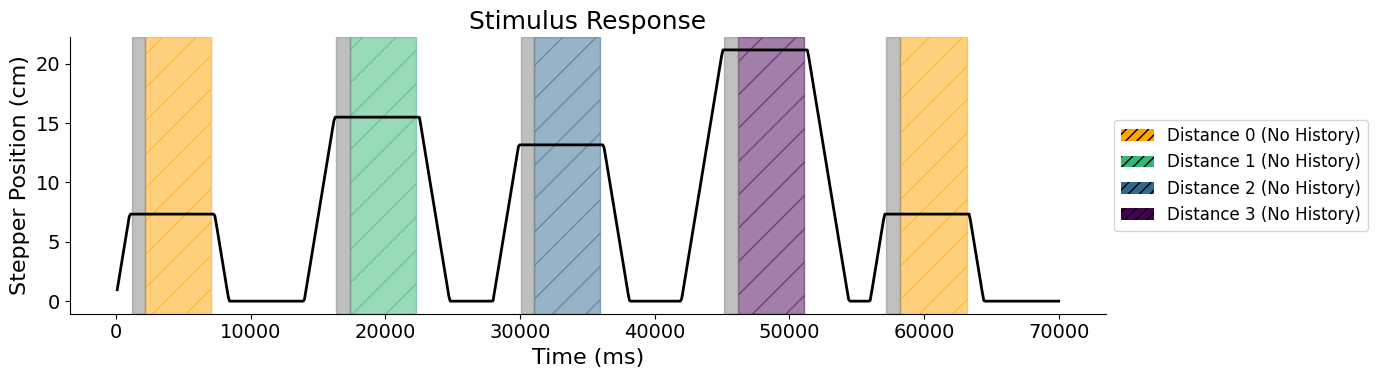

In [25]:
fig = plot_stimulus_response(n_repeats=[0,5])

In [39]:
def plot_cell_stimulus_response(cell, fig_path=None, n_repeats=10, activity_type=None):
    """
    Plot the stimulus response for a given cell.
    
    Parameters:
    -----------
    cell : int
        The cell ID to analyze.
    fig_path : str, optional
        Path to save the figure. If provided, the figure will be saved.
    n_repeats : int or list, optional
        Number of repeats to plot or range of repeats [start, end] to plot.
        Default is 10 (plots first 10 repeats).
    
    Returns:
    --------
    fig : matplotlib.figure.Figure
        The figure object.
    """
    fig = plt.figure(figsize=(14,4))

    # Handle both single number and range inputs for n_repeats
    if isinstance(n_repeats, (list, tuple)) and len(n_repeats) == 2:
        repeats = np.arange(n_repeats[0], n_repeats[1])
    else:
        repeats = np.arange(n_repeats)

    repeat_start = trial_start_time[repeats[0]]*1000
    repeat_end = trial_end_time[repeats[-1]]*1000

    repeats_frames = (frames_time > repeat_start) & (frames_time < repeat_end)

    ax = plt.gca()
    ax2 = ax.twinx()
    ax2.plot(frames_time[repeats_frames], stepper_pos_interp[repeats_frames]/30, lw=2, color='gray', linestyle='--')
    if activity_type == 'spikes':
        ax.plot(frames_time[repeats_frames], D.spikes[cell, repeats_frames].T, lw=2)
    else:
        ax.plot(frames_time[repeats_frames], D.dFF[cell, repeats_frames].T, lw=2)

    for rep in repeats:
        trial_start, trial_end = get_on_times(rep)
        if monocular_sequence[rep] == 1:
            plt.axvspan(trial_start, trial_end, color=colors[trial_sequence[rep]], alpha=0.5, label='Monocular ' + str(trial_sequence[rep]))
        else:
            plt.axvspan(trial_start, trial_end, color=colors[trial_sequence[rep]], alpha=0.5, hatch='/', label='Binocular ' + str(trial_sequence[rep]))
        plt.axvspan(trial_start-1000, trial_start, color='gray', alpha=0.5)
        plt.title('Cell ' + str(D.suite2p_id[cell]) )

    # make a legend for the colors and history/no history
    legend_elements = []
    for i in [0,1,2,3]:
        # No history patch
        patch = plt.Rectangle((0,0), 1, 1, fc=colors[i], label=f'Distance {i} (Monocular)')
        legend_elements.append(patch)
        # History patch with hatch
        patch = plt.Rectangle((0,0), 1, 1, fc=colors[i], hatch='///', label=f'Distance {i} (Binocular)')
        legend_elements.append(patch)
    # Only create one legend and keep it
    ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.1, 0.5))

    ax.set_xlabel('Time (ms)')
    if activity_type == 'spikes':
        ax.set_ylabel('z-scored spikes')
    else:
        ax.set_ylabel('dF/F')

    ax2.set_ylabel('Stepper Position (cm)')

    if fig_path is not None:
        plt.savefig(fig_path + '/cell_' + str(D.suite2p_id[cell]) + '.png')
        plt.close()

    return fig

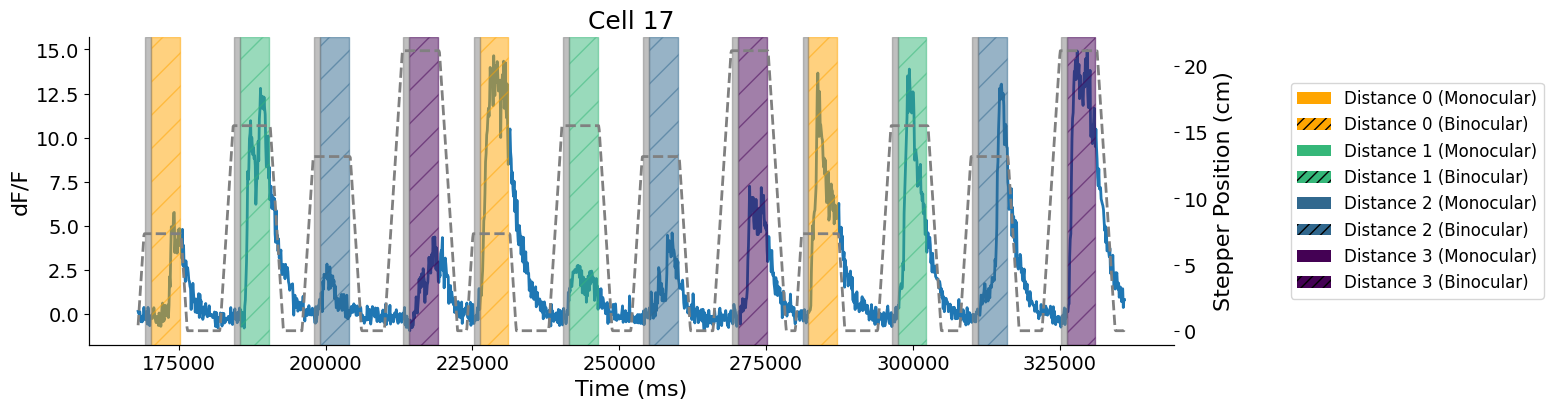

In [69]:
cell_to_show = 17
fig = plot_cell_stimulus_response(cell=np.where(D.suite2p_id == cell_to_show)[0][0], n_repeats=[12,24], activity_type='dFF')

In [70]:
def plot_cell_traces_comparison(cell, whole_repeat='servo'):
    """
    Plot the stimulus response for a given cell with and without history.
    
    Parameters:
    -----------
    cell : int
        The cell ID to analyze.
    whole_repeat : str, optional
        Type of repeat to use. Options are 'servo' or 'movement'.
        Default is 'servo'.
    
    Returns:
    --------
    fig : matplotlib.figure.Figure
        The figure object.
    """
    # Calculate global min and max values from the whole trace using percentiles
    vmin = np.percentile(D.dFF[cell], 1)
    vmax = np.percentile(D.dFF[cell], 99)
    
    cell_id = D.suite2p_id[cell]
    
    # Original 1x2 layout
    all_traces_history, on_mask_history = get_all_traces(cell, whole_repeat=whole_repeat, history=True)
    all_traces_no_history, on_mask_no_history = get_all_traces(cell, whole_repeat=whole_repeat, history=False)

    # Plot with masked array
    fig, axs = plt.subplots(1, 2, figsize=(14, 4))
    # Add a supertitle with the cell ID
    fig.suptitle(f'Cell {cell_id}', fontsize=24)
    # History plot
    
    if whole_repeat == 'servo':
        # Resize the no_history array to match history array dimensions
        resized_no_history = np.zeros_like(all_traces_history)
        resized_mask_no_history = np.zeros_like(all_traces_history, dtype=bool)
        
        resized_no_history[:all_traces_no_history.shape[0], :all_traces_no_history.shape[1]] = all_traces_no_history
        resized_mask_no_history[:all_traces_no_history.shape[0], :all_traces_no_history.shape[1]] = ~on_mask_no_history
        
        masked_resized_no_history = np.ma.array(resized_no_history, mask=resized_mask_no_history)
        
        axs[1].pcolormesh(resized_no_history, cmap='viridis', alpha=1, shading='auto', vmin=vmin, vmax=vmax)
        # Add vertical dashed line at column 20
        axs[1].axvline(x=20, color='white', linestyle='--', linewidth=2)

        axs[0].pcolormesh(all_traces_history, cmap='viridis', alpha=1, shading='auto', vmin=vmin, vmax=vmax)

        axs[0].axvline(x=20, color='white', linestyle='--', linewidth=2)
    
    else:
        masked_all_traces_history = np.ma.array(all_traces_history, mask=~on_mask_history)
        masked_all_traces_no_history = np.ma.array(all_traces_no_history, mask=~on_mask_no_history)
    
        axs[0].pcolormesh(all_traces_history, cmap='viridis', alpha=0.7, shading='auto', vmin=vmin, vmax=vmax)
        axs[0].pcolormesh(masked_all_traces_history, cmap='viridis', alpha=1, shading='auto', vmin=vmin, vmax=vmax)
        # Adjust the width of the second plot to match the first one
        aspect_ratio = all_traces_history.shape[1] / all_traces_no_history.shape[1]
        
        axs[1].set_box_aspect(1/aspect_ratio)
        axs[1].pcolormesh(all_traces_no_history, cmap='viridis', alpha=1, shading='auto', vmin=vmin, vmax=vmax)
        axs[1].pcolormesh(masked_all_traces_no_history, cmap='viridis', alpha=1, shading='auto', vmin=vmin, vmax=vmax)
    
    axs[0].set_title('With History')
    axs[1].set_title('No History')

    plt.subplots_adjust(wspace=-0.5)

    # set labels
    axs[0].set_xlabel('Time (ms)')
    axs[0].set_ylabel('Repeat Number')
    axs[1].set_xlabel('Time (ms)')
    axs[1].set_ylabel('Repeat Number')

    # add colorbar
    cbar = plt.colorbar(axs[0].pcolormesh(all_traces_history, cmap='viridis', alpha=1, shading='auto', vmin=vmin, vmax=vmax))
    cbar.set_label('dF/F')

    plt.tight_layout()
    return fig

# Example usage
# fig = plot_cell_traces_comparison(np.where(D.suite2p_id == 113)[0][0], whole_repeat='movement')
fig = plot_cell_traces_comparison(np.where(D.suite2p_id == 175)[0][0], whole_repeat='servo')

AxisError: axis 1 is out of bounds for array of dimension 1

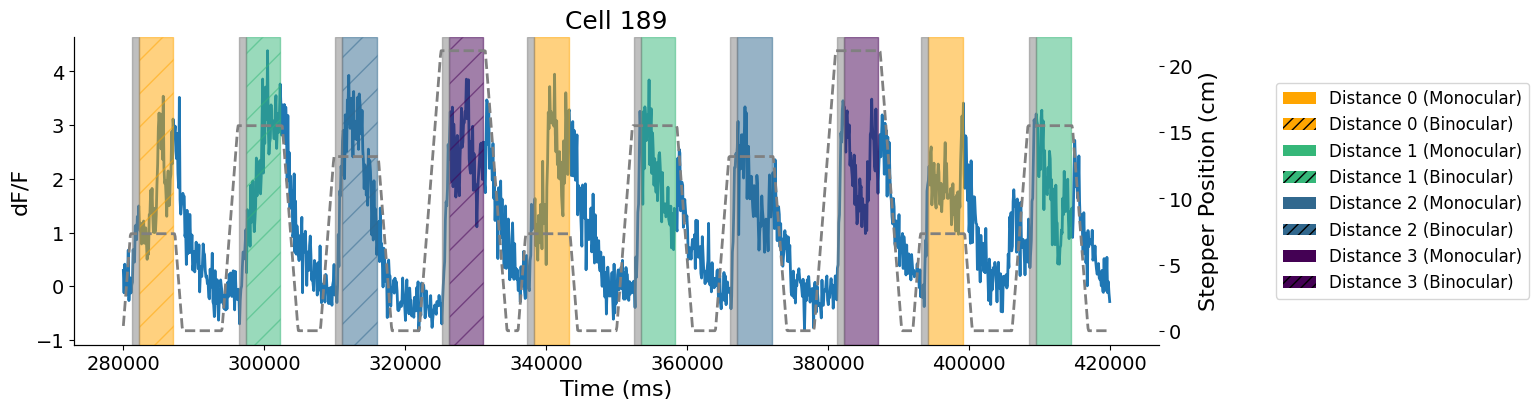

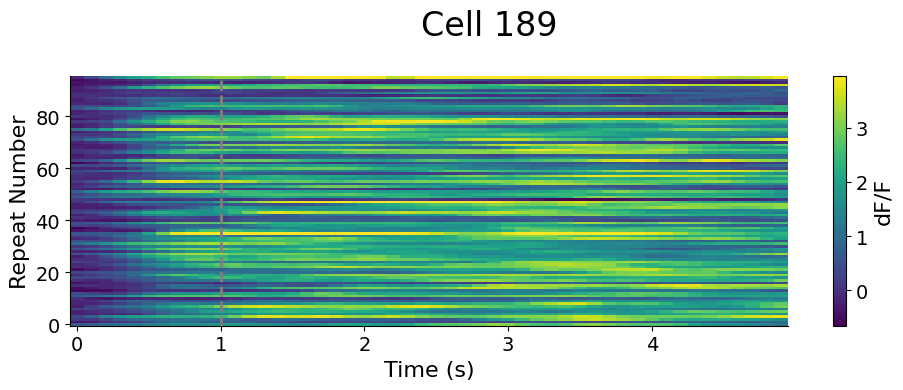

In [87]:
def plot_cell_traces_comparison(cell, activity_mode='dFF'):
    """
    Plot the stimulus response for a given cell.
    
    Parameters:
    -----------
    cell : int
        The cell ID to analyze.
    whole_repeat : str, optional
        Type of repeat to use. Options are 'servo' or 'movement'.
        Default is 'servo'.
    
    Returns:
    --------
    fig : matplotlib.figure.Figure
        The figure object.
    """
    # Calculate global min and max values from the whole trace using percentiles
    if activity_mode == 'dFF':
        vmin = np.percentile(D.dFF[cell], 1)
        vmax = np.percentile(D.dFF[cell], 99)
    elif activity_mode == 'spikes':
        vmin = np.percentile(D.spikes[cell], 1)
        vmax = np.percentile(D.spikes[cell], 99)
    
    cell_id = D.suite2p_id[cell]
    
    # Plot with masked array
    fig, ax = plt.subplots(figsize=(10, 4))
    # Add a supertitle with the cell ID
    fig.suptitle(f'Cell {cell_id}', fontsize=24)
    
    all_traces = get_all_traces(cell, whole_repeat='servo', history=False, activity_mode=activity_mode)
    
    # Get the number of frames for x-axis
    num_frames = all_traces.shape[1]
    # Create time axis in seconds (each frame is 100ms = 0.1s)
    time_axis = np.arange(num_frames) * 0.1
    
    # Plot all traces with proper time axis
    mesh = ax.pcolormesh(time_axis, np.arange(all_traces.shape[0]), all_traces, 
                         cmap='viridis', alpha=1, shading='auto', vmin=vmin, vmax=vmax)
    
    # set labels
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Repeat Number')
    
    # add colorbar
    cbar = plt.colorbar(mesh)
    if activity_mode == 'dFF':
        cbar.set_label('dF/F')
    elif activity_mode == 'spikes':
        cbar.set_label('z-scored spks')
    
    # add vertical line at stimulus onset (frame 20 = 2.0s)
    ax.axvline(x=1.0, color='gray', linestyle='--', linewidth=2, label='Stimulus Onset')

    plt.tight_layout()
    return fig

# Example usage
# fig = plot_cell_traces_comparison(np.where(D.suite2p_id == 113)[0][0], whole_repeat='movement')
cell_to_show = 189
fig = plot_cell_stimulus_response(cell=np.where(D.suite2p_id == cell_to_show)[0][0], n_repeats=[20,30], activity_type='dFF')
fig = plot_cell_traces_comparison(np.where(D.suite2p_id == cell_to_show)[0][0], activity_mode='dFF')

In [574]:
# plot for all the cells for spks
fig_path = create_new_result_dir(results_path, r'dff_traces')
for cell in range(D.spikes.shape[0]):
    cell_id = D.suite2p_id[cell]
    fig = plot_cell_traces_comparison(cell, activity_mode='dFF')
    fig.savefig(os.path.join(fig_path, f'cell_{cell_id}_spks.png'))
    plt.close(fig)

Directory dff_traces already exists


In [73]:
# make a directory of raw traces
fig_path = create_new_result_dir(results_path, r'raw_traces')

for cell in np.arange(D.dFF.shape[0]):
    fig = plot_cell_traces_comparison(cell, whole_repeat='servo')
    fig.savefig(os.path.join(fig_path, f'cell_{cell}_servo.png'))
    plt.close(fig)
    fig = plot_cell_traces_comparison(cell, whole_repeat='movement')
    fig.savefig(os.path.join(fig_path, f'cell_{cell}_movement.png'))
    plt.close(fig)

Directory raw_traces already exists


In [54]:
print(np.shape(D.dFF))

(298, 12100)


In [393]:
def plot_history_distance_comparison(cell):
    """
    Plot the mean traces for different distances with and without history for a given cell.
    
    Parameters:
    -----------
    cell_id : int
        The ID of the cell to plot.
    
    
    Returns:
    --------
    fig : matplotlib.figure.Figure
        The figure object.
    """
    # Create figure with different widths for the two subplots
    fig = plt.figure(figsize=(14, 6))
    
    # Create GridSpec to control subplot sizes
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 1])
    # Create axes with the specified width ratios
    ax1 = fig.add_subplot(gs[0])  # History subplot
    ax2 = fig.add_subplot(gs[1])  # No-history subplot
    
    axs = [ax1, ax2]
    
    plt.suptitle(f'Cell {D.suite2p_id[cell]}', fontsize=24)

    # Define colors for different distances
    colors = setup_plot_style()
    whole_repeat = 'servo'
    distances = [1, 2, 3]
    
    # Calculate global min and max values from the cell's overall response using percentiles
    vmin = np.percentile(D.dFF[cell], 1)
    vmax = np.percentile(D.dFF[cell], 99)

    # Plot for both with and without history
    titles = [f'History ({whole_repeat.capitalize()})', f'No-History ({whole_repeat.capitalize()})']
    history_values = [True, False]  # First plot is with history, second is without
    
    for ax_idx, (ax, title, history) in enumerate(zip(axs, titles, history_values)):
        # Plot each distance
        for i, distance in enumerate(distances):
            mean_trace, sem_trace = get_all_traces(cell, distance=distance, whole_repeat=whole_repeat, 
                                                  history=history, mean_trace=True)
            
            # Plot mean trace
            color = colors[i % len(colors)]
            ax.plot(mean_trace.T, color=color, linewidth=2, label=f'Distance {distance}')
            
            # Plot SEM as shaded area
            x_range = np.arange(mean_trace.shape[0])
            ax.fill_between(x_range, 
                           mean_trace - sem_trace, 
                           mean_trace + sem_trace, 
                           color=color, alpha=0.2)

        # Add vertical line at index 20
        ax.axvline(x=20, color='black', linestyle='--', linewidth=1.5)

        # Set labels and title
        ax.set_xlabel('Time (frames)')
        ax.set_ylabel('dF/F')
        ax.set_title(title)
        ax.legend()
        ax.set_ylim(vmin, vmax)

    plt.tight_layout()
    return fig

In [88]:
def plot_distance_comparison(cell, conditions=None):
    """
    Plot the mean traces for different distances with and without history for a given cell.
    
    Parameters:
    -----------
    cell_id : int
        The ID of the cell to plot.
    
    Returns:
    --------
    fig : matplotlib.figure.Figure
        The figure object.
    """
    # Calculate number of repeats
    num_distances = 4
    num_conditions = 4  # monocular/binocular x history/no-history
    num_repeats = len(trial_sequence) // num_distances // num_conditions

    # Define conditions for each subplot
    if conditions is None:
        conditions = [
            {'history': False, 'monocular': True, 'title': 'No History (Monocular)'},
            {'history': True, 'monocular': True, 'title': 'History (Monocular)'},
            {'history': False, 'monocular': False, 'title': 'No History (Binocular)'},
            {'history': True, 'monocular': False, 'title': 'History (Binocular)'}
    ]
    
    # Create figure with a number of subplots based on the number of conditions
    num_conditions = len(conditions)
    fig = plt.figure(figsize=(len(conditions)*6, 4))
    
    # Create GridSpec to control subplot sizes based on conditions
    gs = fig.add_gridspec(1, num_conditions)  # 1 row for all conditions
    
    # Create axes for each condition
    axs = [fig.add_subplot(gs[0, i]) for i in range(num_conditions)]
    
    plt.suptitle(f'Cell {D.suite2p_id[cell]}', fontsize=24)

    # Define colors for different distances
    colors = setup_plot_style()
    distances = [0, 1, 2, 3]
    
    # Calculate global min and max values from the cell's overall response using percentiles
    vmin = np.percentile(D.dFF[cell], 1)
    vmax = np.percentile(D.dFF[cell], 99)

    
    for ax, condition in zip(axs, conditions):
        # Plot each distance
        for i, distance in enumerate(distances):
            mean_trace, sem_trace = get_all_traces(cell, distance=distance, whole_repeat='servo',
                                                  history=condition['history'], monocular=condition['monocular'],
                                                  mean_trace=True)
            
            # Plot mean trace
            color = colors[i % len(colors)]
            ax.plot(mean_trace.T, color=color, linewidth=2, label=f'Distance {distance}')
            
            # Plot SEM as shaded area
            x_range = np.arange(mean_trace.shape[0])
            ax.fill_between(x_range, 
                           mean_trace - sem_trace, 
                           mean_trace + sem_trace, 
                           color=color, alpha=0.2)

        # Add vertical line at index 20
        ax.axvline(x=10, color='black', linestyle='--', linewidth=1.5)

        # Set labels and title
        ax.set_xlabel('Time (frames)')
        ax.set_ylabel('z-scored dF/F')
        ax.set_title(condition['title'])
        ax.legend()
        ax.set_ylim(vmin, vmax)

    plt.tight_layout()
    return fig

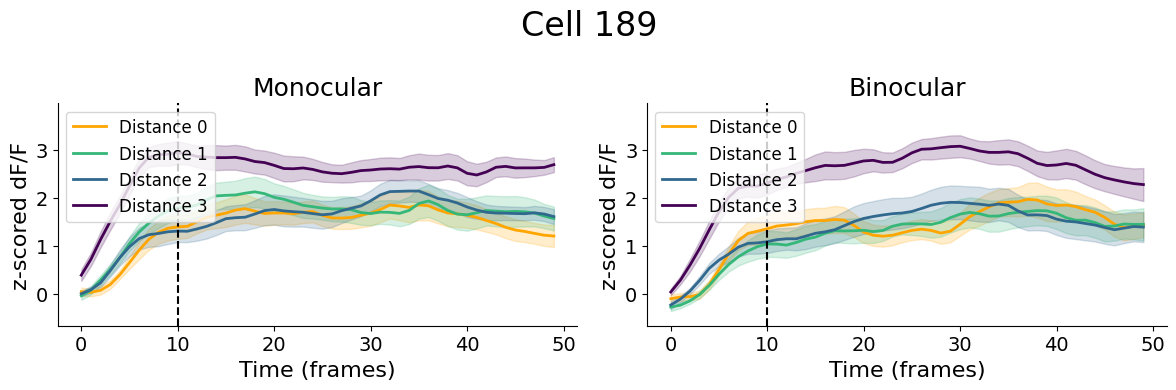

In [89]:
# # example of distance comparison
cell_to_show = 189
conditions = [
            {'history': False, 'monocular': True, 'title': 'Monocular'},
            {'history': False, 'monocular': False, 'title': 'Binocular'}]
fig = plot_distance_comparison(np.where(D.suite2p_id == cell_to_show)[0][0], conditions=conditions)

In [102]:
# Create output directory if it doesn't exist
fig_path = create_new_result_dir(results_path, r'distance_comparison')

# Plot distance comparison for all cells
for cell in range(D.dFF.shape[0]):
    fig = plot_distance_comparison(cell, conditions=conditions)
    
    # Save figure
    filename = f'{fig_path}/cell_{D.suite2p_id[cell]}_distance_comparison.png'
    fig.savefig(filename)
    plt.close(fig)  # Close figure to free memory

Creating directory: distance_comparison


# Now for responsivness

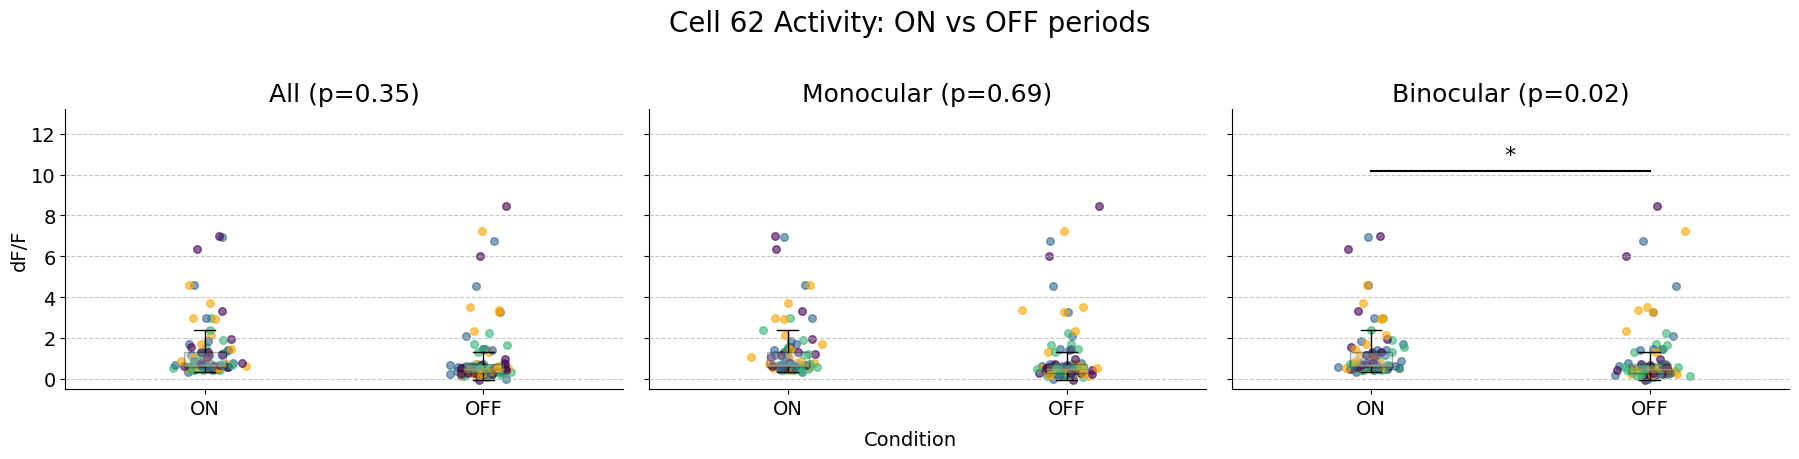

In [93]:
def analyze_cell_responsiveness(cell, monocular=None):
    """
    Analyzes if a cell is responsive to stimuli under a specific condition.
    
    Args:
        cell: Cell index to analyze
        condition: Condition to analyze ('monocular', 'binocular', or 'all')
        
    Returns:
        tuple: (is_responsive, p_value) where is_responsive is True if the cell is 
               significantly more active during ON periods (p < 0.05 and ON median > OFF median)
    """
    # Determine which trials to use based on condition
    if monocular is None:
        repeat_indices = np.arange(len(trial_sequence))
    elif monocular:
        repeat_indices = np.where(monocular_sequence == monocular)[0]
    else:
        repeat_indices = np.where(monocular_sequence == 0)[0]
    
    # Calculate medians for this condition
    on_max = []
    off_max = []
    
    for repeat in repeat_indices:
        on_trace = D.dFF[cell, get_on_frames(repeat)]
        off_trace = D.dFF[cell, get_off_frames(repeat)]
        
        on_max.append(np.percentile(on_trace, 95))
        off_max.append(np.percentile(off_trace, 95))
    
    # Perform t-test
    t_stat, p_val = ttest_ind(on_max, off_max)
    
    # Determine if cell is responsive (p < 0.05 and median ON > median OFF)
    is_responsive = (p_val < 0.05) and (np.median(on_max) > np.median(off_max))
    
    return is_responsive, p_val

def plot_cell_responsiveness(cell):
    """
    Creates a figure with 3 subplots showing cell responsiveness in different conditions.
    
    Args:
        cell: Cell index to analyze
        
    Returns:
        fig: The matplotlib figure object
    """
    # Create a figure with 3 subplots
    fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)

    # Add suptitle higher up and make it bigger
    fig.suptitle(f'Cell {D.suite2p_id[cell]} Activity: ON vs OFF periods', fontsize=20, y=1.1)

    # Define conditions to plot
    conditions = [None, True, False]

    # Calculate medians and prepare data for all conditions
    all_medians = []
    
    for i, condition in enumerate(conditions):
        # Get responsiveness data using the analyze function
        is_responsive, p_val = analyze_cell_responsiveness(cell, condition)
        
        # Determine which trials to use based on condition
        if condition == 'monocular':
            repeat_indices = np.where(monocular_sequence == 1)[0]
        elif condition == 'binocular':
            repeat_indices = np.where(monocular_sequence == 0)[0]
        else:  # 'all'
            repeat_indices = np.arange(len(trial_sequence))
        
        # Calculate 95th percentile for this condition
        on_percentiles = []
        off_percentiles = []
        
        for repeat in repeat_indices:
            on_trace = D.dFF[cell, get_servo_on_frames(repeat)]
            off_trace = D.dFF[cell, get_off_frames(repeat)]
            
            on_percentile = np.percentile(on_trace, 95)
            off_percentile = np.percentile(off_trace, 95)
            
            on_percentiles.append(on_percentile)
            off_percentiles.append(off_percentile)
            all_medians.extend([on_percentile, off_percentile])
        
        # Set a consistent bar height for all plots
        bar_height = np.max(all_medians) * 1.2 if all_medians else 0
        
        # Create the box plot with transparent boxes
        data = [on_percentiles, off_percentiles]
        bp = axes[i].boxplot(data, patch_artist=True, showfliers=False, labels=['ON', 'OFF'])
        
        # Set colors for the boxes with transparency
        colors_boxes = ['lightblue', 'lightgreen']
        for patch, color in zip(bp['boxes'], colors_boxes):
            patch.set_facecolor(color)
            patch.set_alpha(0.3)  # Make boxes transparent
        
        # Add individual data points (scatter)
        for j, repeat in enumerate(repeat_indices):
            # Add jitter to x position to better visualize points
            x_on = np.random.normal(1, 0.05, 1)
            x_off = np.random.normal(2, 0.05, 1)
            
            axes[i].scatter(x_on, on_percentiles[j], alpha=0.6, s=30, color=colors[trial_sequence[repeat]])
            axes[i].scatter(x_off, off_percentiles[j], alpha=0.6, s=30, color=colors[trial_sequence[repeat]])
        
        # Set title with p-value (two decimal places)
        if condition is None:
            condition_title = "All"
        elif condition is True:
            condition_title = "Monocular"
        elif condition is False:
            condition_title = "Binocular"
        else:
            condition_title = str(condition)
        axes[i].set_title(f'{condition_title.capitalize()} (p={p_val:.2f})', fontsize=18)
        
        # Add significance bar at consistent height across all plots
        if p_val < 0.05 and is_responsive:
            axes[i].plot([1, 2], [bar_height, bar_height], 'k-', linewidth=1.5)
            
            # Add more asterisks based on significance level
            if p_val < 0.001:
                axes[i].text(1.5, bar_height * 1.05, '***', horizontalalignment='center', fontsize=16)
            elif p_val < 0.01:
                axes[i].text(1.5, bar_height * 1.05, '**', horizontalalignment='center', fontsize=16)
            else:
                axes[i].text(1.5, bar_height * 1.05, '*', horizontalalignment='center', fontsize=16)
        
        axes[i].grid(axis='y', linestyle='--', alpha=0.7)
        
        # Set y-limit to ensure bar is visible but not too close to title
        axes[i].set_ylim(top=bar_height * 1.3)

    # Set common labels
    fig.text(0.5, 0.01, 'Condition', ha='center', fontsize=14)
    fig.text(0.00, 0.5, 'dF/F', va='center', rotation='vertical', fontsize=14)

    plt.tight_layout()
    plt.subplots_adjust(top=0.85, bottom=0.15)
    
    return fig

# Example usage
cell_to_show = 62
cell = np.where(D.suite2p_id == cell_to_show)[0][0]
fig = plot_cell_responsiveness(cell)

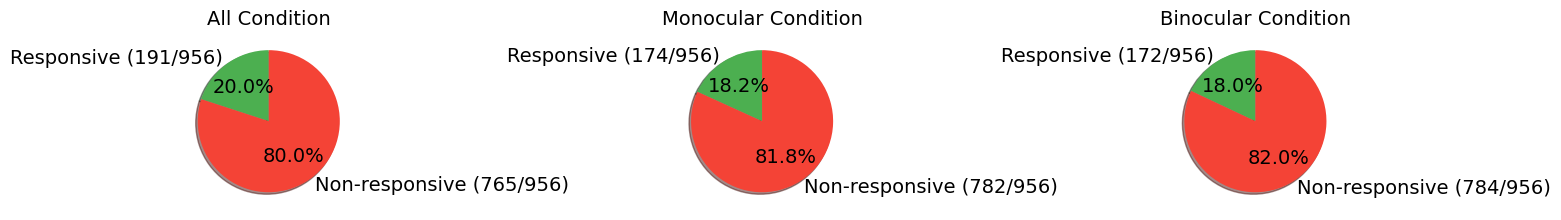

In [958]:
# Initialize counters for responsive cells
responsive_all = 0
responsive_monocular = 0
responsive_binocular = 0
total_cells = D.dFF.shape[0]

# Analyze each cell
for cell in range(total_cells):
    is_responsive_all, _ = analyze_cell_responsiveness(cell, None)
    is_responsive_monocular, _ = analyze_cell_responsiveness(cell, True)
    is_responsive_binocular, _ = analyze_cell_responsiveness(cell, False)
    
    # Count responsive cells
    if is_responsive_all:
        responsive_all += 1
    if is_responsive_monocular:
        responsive_monocular += 1
    if is_responsive_binocular:
        responsive_binocular += 1

# Create pie charts for each condition
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Data for pie charts
conditions = ['All', 'Monocular', 'Binocular']
responsive_counts = [responsive_all, responsive_monocular, responsive_binocular]
non_responsive_counts = [total_cells - count for count in responsive_counts]

# Create pie charts
for i, (condition, responsive, non_responsive) in enumerate(zip(conditions, responsive_counts, non_responsive_counts)):
    axes[i].pie([responsive, non_responsive], 
                labels=[f'Responsive ({responsive}/{total_cells})', f'Non-responsive ({non_responsive}/{total_cells})'],
                autopct='%1.1f%%',
                colors=['#4CAF50', '#F44336'],
                startangle=90,
                shadow=True)
    axes[i].set_title(f'{condition} Condition', fontsize=14)

plt.tight_layout()
plt.show()

In [91]:
def plot_distance_and_rf_comparison(cell):
    """
    Plot distance traces and RF values across distances for all conditions.
    
    Parameters:
    -----------
    cell : int
        The cell ID to analyze.
    
    Returns:
    --------
    fig : matplotlib.figure.Figure
        The figure object.
    """
    conditions = [
        {'history': False, 'monocular': True, 'title': 'No History (Monocular)'},
        {'history': False, 'monocular': False, 'title': 'No History (Binocular)'},
    ]
    
    # Create figure with 2 rows, 4 columns
    fig = plt.figure(figsize=(12, 8))
    gs = fig.add_gridspec(2, 2)
    axes_top = [fig.add_subplot(gs[0, i]) for i in range(2)]
    axes_bottom = [fig.add_subplot(gs[1, i]) for i in range(2)]
    
    plt.suptitle(f'Cell {D.suite2p_id[cell]}', fontsize=24)
    
    colors = setup_plot_style()
    distances = [0, 1, 2, 3]
    
    # Calculate global min/max for top row
    vmin = np.percentile(D.dFF[cell], 1)
    vmax = np.percentile(D.dFF[cell], 99)

    # Plot both rows
    for idx, condition in enumerate(conditions):
        # Top row - distance traces
        ax_top = axes_top[idx]
        for i, distance in enumerate(distances):
            mean_trace, sem_trace = get_all_traces(cell, distance=distance, whole_repeat='servo',
                                                 history=condition['history'], monocular=condition['monocular'],
                                                 mean_trace=True)
            
            ax_top.plot(mean_trace.T, color=colors[i], linewidth=2, label=f'Distance {distance}')
            ax_top.fill_between(range(len(mean_trace)), 
                              mean_trace - sem_trace,
                              mean_trace + sem_trace,
                              color=colors[i], alpha=0.2)
        
        ax_top.axvline(x=10, color='black', linestyle='--', linewidth=1.5)
        ax_top.set_xlabel('Time (frames)')
        ax_top.set_ylabel('dF/F')
        ax_top.set_title(condition['title'])
        ax_top.legend()
        ax_top.set_ylim(vmin, vmax)

        # Bottom row - RF values
        ax_bottom = axes_bottom[idx]
        rf_values = []
        for distance in distances:
            on_traces = get_all_traces(cell, whole_repeat='servo', 
                                     distance=distance,
                                     history=condition['history'],
                                     monocular=condition['monocular'])
            # get the 95th percentile of the on traces
            on_traces_95 = np.percentile(on_traces, 95, axis=1)
            rf_values.append(on_traces_95)

        f_stat, p_value = f_oneway(*rf_values)
        bp = ax_bottom.boxplot(rf_values, patch_artist=True, labels=distances)
        
        for element in ['boxes', 'whiskers', 'caps', 'medians']:
            for item in bp[element]:
                item.set_color('black')
                item.set_linewidth(1)
        for box in bp['boxes']:
            box.set_facecolor('none')

        for i, rf_vals in enumerate(rf_values):
            x = np.random.normal(i+1, 0.04, size=len(rf_vals))
            ax_bottom.scatter(x, rf_vals, alpha=0.8, color=colors[i], s=20)

        # # Check if p_value is significant and if the cell is responsive for the monocular condition
        
        if p_value < 0.05 and analyze_cell_responsiveness(cell, condition['monocular'])[0]:
            y_max = max([max(vals) for vals in rf_values])
            bar_height = y_max * 1.1
            ax_bottom.plot([1, len(distances)], [bar_height, bar_height], 'k-', linewidth=1.5)
            ax_bottom.text((1 + len(distances))/2, bar_height*1.02, '*', ha='center', va='bottom')

        ax_bottom.set_title(f'p={p_value:.3f}')
        ax_bottom.set_xlabel('Distance')
        ax_bottom.set_ylabel('dF/F')

    plt.tight_layout()
    return fig


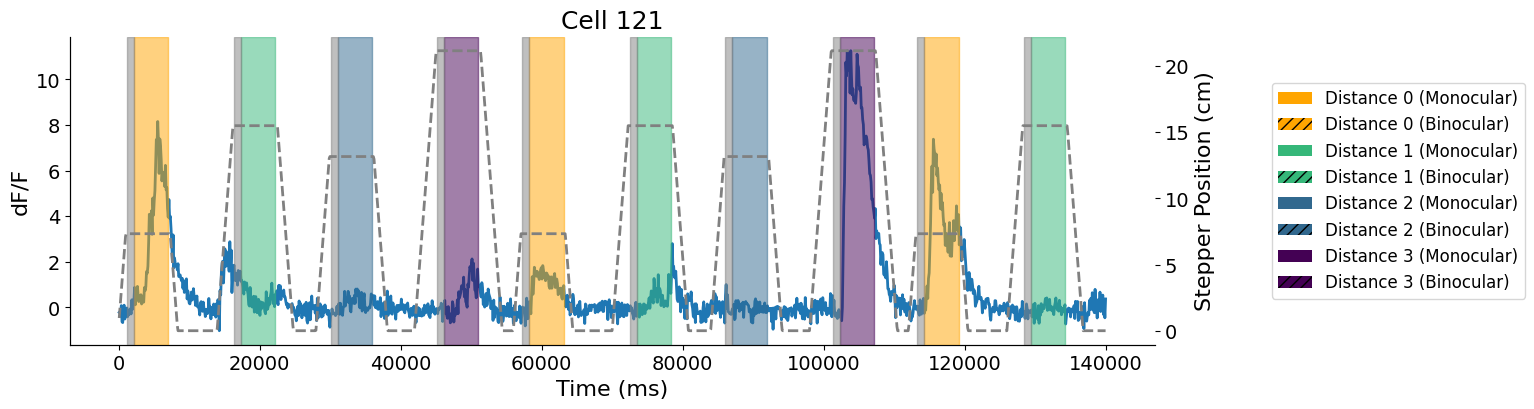

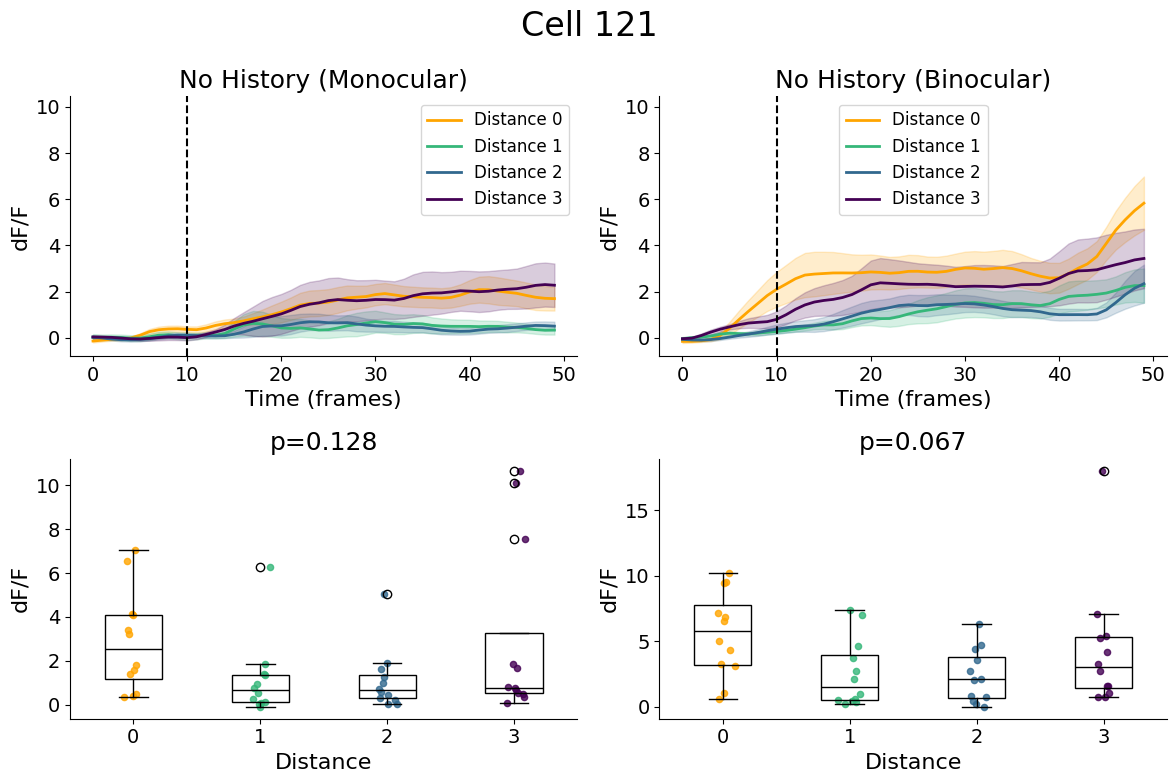

In [102]:
cell_to_show = 121
fig = plot_cell_stimulus_response(cell=np.where(D.suite2p_id == cell_to_show)[0][0], n_repeats=[0,10], activity_type='dFF')
fig = plot_distance_and_rf_comparison(np.where(D.suite2p_id == cell_to_show)[0][0])

In [969]:
# for all responsive cells, be monoculr or binocular, plot the distance and rf comparison
responsive_cells = []
for cell in range(D.dFF.shape[0]):
    is_responsive_monocular, _ = analyze_cell_responsiveness(cell, True)
    is_responsive_binocular, _ = analyze_cell_responsiveness(cell, False)
    if is_responsive_monocular or is_responsive_binocular:
        responsive_cells.append(cell)


fig_path = create_new_result_dir(results_path, r'responsive_cells_response')
for cell in responsive_cells:
    fig = plot_distance_and_rf_comparison(cell)
    fig.savefig(os.path.join(fig_path, f'cell_{D.suite2p_id[cell]}_rf.png'))
    plt.close(fig)




Creating directory: responsive_cells_response


In [123]:
def is_cell_responsive(cell, plot=False, monocular=None):
    """
    Determines if a cell is significantly more active during on times than off times.
    
    Args:
        cell: Cell index to analyze
        plot: Whether to plot the boxplot of on vs off activity
        
    Returns:
        bool: True if cell is significantly more active during on times
    """
    # Use raw dFF data for the cell without z-scoring
    all_traces_no_history, _ = get_all_traces(cell, whole_repeat='servo', history=False, monocular=monocular)
    all_traces = all_traces_no_history

    # have two groups, one will be the first 20 frames, the other will be the last 25 frames, where rows are repeats and columns are frames
    off_activity = all_traces[:, :20]
    on_activity = all_traces[:, 20:]

    off_mean = np.mean(off_activity, axis=1)
    on_mean = np.mean(on_activity, axis=1)

    # Perform t-test
    _, p_value = ttest_ind(on_mean, off_mean)
    
    if plot:
        # Create boxplot
        fig, ax = plt.subplots(figsize=(6, 4))
        data = [on_mean, off_mean]
        bp = ax.boxplot(data, patch_artist=True, showfliers=False, labels=['ON', 'OFF'])
        
        # Customize boxplot colors and line thickness
        colors = ['blue', 'gray']
        for i, (box, whisker, cap, median) in enumerate(zip(bp['boxes'], bp['whiskers'][::2], bp['caps'][::2], bp['medians'])):
            box.set_facecolor('none')
            box.set_linewidth(2)
            box.set_edgecolor(colors[i])
            
            whisker.set_linewidth(2)
            whisker.set_color(colors[i])
            
            bp['whiskers'][i*2+1].set_linewidth(2)
            bp['whiskers'][i*2+1].set_color(colors[i])
            
            cap.set_linewidth(2)
            cap.set_color(colors[i])
            
            bp['caps'][i*2+1].set_linewidth(2)
            bp['caps'][i*2+1].set_color(colors[i])
            
            median.set_linewidth(2)
            median.set_color(colors[i])

        # add p-value annotation in the title
        ax.set_title(f'Cell {D.suite2p_id[cell]} Activity (p={p_value:.3f})')
    
        ax.set_ylabel('dFF')
        plt.tight_layout()
        
    # Check if mean on activity is greater and p-value significant
    return (np.mean(on_activity) > np.mean(off_activity))

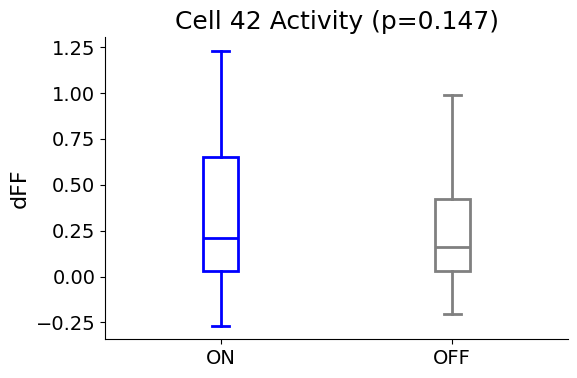

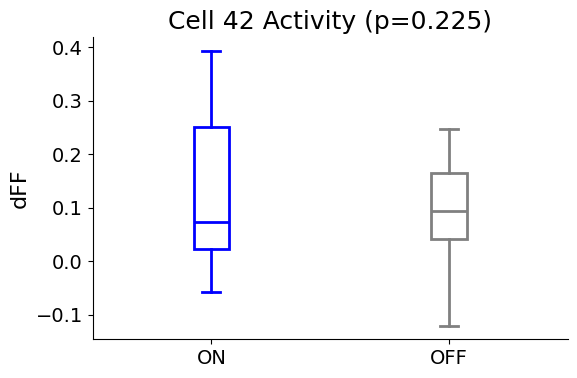

In [122]:
fig = is_cell_responsive(np.where(D.suite2p_id == 42)[0][0], monocular=True, plot=True)
fig = is_cell_responsive(np.where(D.suite2p_id == 42)[0][0], monocular=False, plot=True)

Found 216 responsive to on times out of 412 total cells


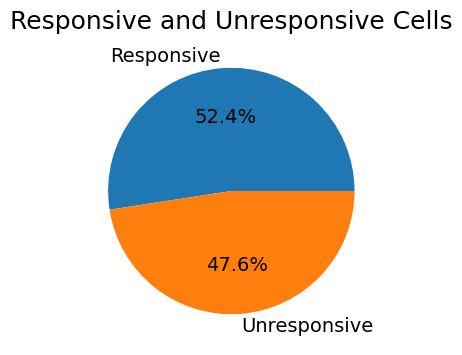

In [196]:
responsive_cells = []
unresponsive_cells = []
for cell in range(D.dFF.shape[0]):
    is_responsive = is_cell_responsive(cell)
    if is_responsive:
        responsive_cells.append(cell)
    else:
        unresponsive_cells.append(cell)
     
print(f"Found {len(responsive_cells)} responsive to on times out of {D.dFF.shape[0]} total cells")

# make a pie plot showing the percentage and number of responsive and unresponsive cells
fig, ax = plt.subplots(figsize=(6, 4))
ax.pie([len(responsive_cells), len(unresponsive_cells)], labels=['Responsive', 'Unresponsive'], autopct='%1.1f%%')
ax.set_title('Responsive and Unresponsive Cells')
plt.show()

# save the pie chart to results_path
fig.savefig(os.path.join(results_path, 'responsive_and_unresponsive_cells.png'))
plt.close(fig)



In [125]:
fig_path_responsive = create_new_result_dir(results_path, r'responsive_cells')
fig_path_unresponsive = create_new_result_dir(results_path, r'unresponsive_cells')

for cell in responsive_cells:
    fig = plot_distance_comparison(cell, conditions=conditions)
    fig.savefig(os.path.join(fig_path_responsive, f'cell_{D.suite2p_id[cell]}_servo.png'))
    plt.close(fig)

for cell in unresponsive_cells:
    fig = plot_distance_comparison(cell, conditions=conditions)
    fig.savefig(os.path.join(fig_path_unresponsive, f'cell_{D.suite2p_id[cell]}_servo.png'))
    plt.close(fig)


Creating directory: responsive_cells
Creating directory: unresponsive_cells


# Now for modulation

In [127]:
def find_receptive_field(cell):
    """
    Find the receptive field of a cell.
    """
    all_traces, _ = get_all_traces(cell=cell, whole_repeat='servo')
    mean_trace = np.mean(all_traces, axis=0)

    # find the max of mean trace and the index of the max
    max_index = np.argmax(mean_trace)

    return max_index

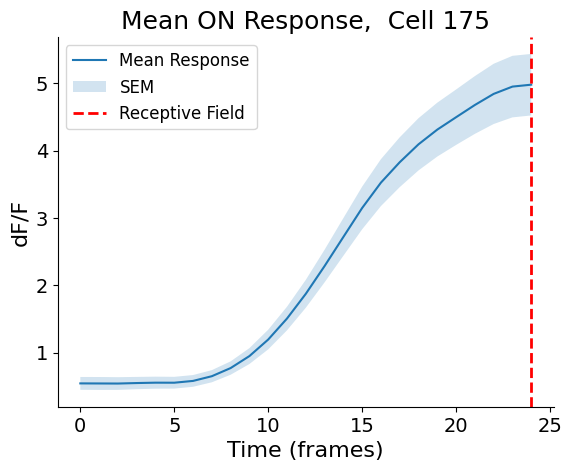

In [130]:
# find the receptive field of the cell
cell_to_show = 175
all_traces, _ = get_all_traces(np.where(D.suite2p_id == cell_to_show)[0][0], whole_repeat='servo')
mean_trace = np.mean(all_traces, axis=0)
sem_trace = np.std(all_traces, axis=0) / np.sqrt(all_traces.shape[0])

# find the max of mean trace and the index of the max
receptive_field = find_receptive_field(np.where(D.suite2p_id == cell_to_show)[0][0])

plt.figure()
plt.plot(mean_trace, label='Mean Response')
plt.fill_between(np.arange(len(mean_trace)), mean_trace - sem_trace, mean_trace + sem_trace, alpha=0.2, label='SEM')
plt.axvline(x=receptive_field, color='red', linestyle='--', linewidth=2, label='Receptive Field')
plt.xlabel('Time (frames)')
plt.ylabel('dF/F')
plt.title('Mean ON Response,  Cell ' + str(D.suite2p_id[np.where(D.suite2p_id == cell_to_show)[0][0]]))
plt.legend()
plt.show()

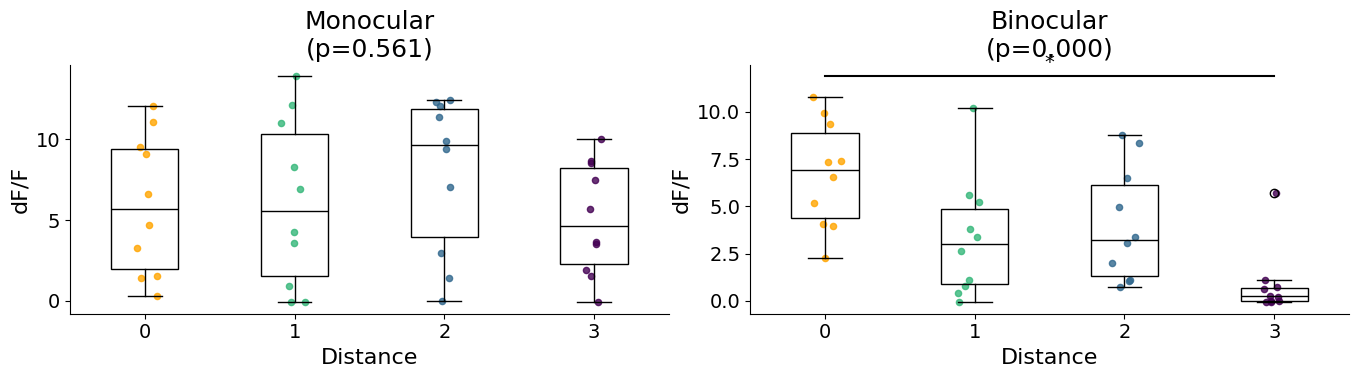

Directory distance_comparison already exists


In [134]:
def plot_rf_distance_comparison(cell, conditions=None):
    """
    Plot receptive field values across distances for all conditions.
    
    Parameters:
    -----------
    cell : int
        The cell ID to analyze.
    """

    if conditions is None:
        conditions = [
            {'history': False, 'monocular': True, 'title': 'No History (Monocular)'},
            {'history': True, 'monocular': True, 'title': 'History (Monocular)'},
            {'history': False, 'monocular': False, 'title': 'No History (Binocular)'},
            {'history': True, 'monocular': False, 'title': 'History (Binocular)'}
        ]

    fig, axes = plt.subplots(1, len(conditions), figsize=(len(conditions)*7, 4))
    axes = axes.flatten()
    distances = [0, 1, 2, 3]
    rf_index = find_receptive_field(cell)

    for ax_idx, condition in enumerate(conditions):
        # Get RF values for each distance
        rf_values = []
        for distance in distances:
            traces = get_all_traces(cell, whole_repeat='servo', 
                                     distance=distance, 
                                     history=condition['history'], 
                                     monocular=condition['monocular'])
            if traces.shape[1] > 25:
                traces = traces[:, 20:]
            rf_values.append(traces[:, rf_index])

        # Perform one-way ANOVA
        f_stat, p_value = f_oneway(*rf_values)

        # Create boxplot
        bp = axes[ax_idx].boxplot(rf_values, patch_artist=True, labels=distances)

        # Set colors for boxes and other elements
        for element in ['boxes', 'whiskers', 'caps', 'medians']:
            for i, item in enumerate(bp[element]):
                item.set_color('black')
                item.set_linewidth(1)

        # Remove fill from boxes
        for box in bp['boxes']:
            box.set_facecolor('none')

        axes[ax_idx].set_title(f'{condition["title"]}\n(p={p_value:.3f})')
        axes[ax_idx].set_xlabel('Distance')
        axes[ax_idx].set_ylabel('dF/F')

        # Add scatter points
        for i, rf_vals in enumerate(rf_values):
            x = np.random.normal(i+1, 0.04, size=len(rf_vals))
            axes[ax_idx].scatter(x, rf_vals, alpha=0.8, color=colors[i % len(colors)], s=20)

        # Add significance bar if p < 0.05
        if p_value < 0.05:
            y_max = max([max(vals) for vals in rf_values])
            bar_height = y_max * 1.1
            axes[ax_idx].plot([1, len(distances)], [bar_height, bar_height], 'k-', linewidth=1.5)
            axes[ax_idx].text((1 + len(distances))/2, bar_height*1.02, '*', ha='center', va='bottom')

    plt.tight_layout()
    return fig

# Test the function
# fig = plot_distance_comparison(np.where(D.suite2p_id == cell_to_show)[0][0])
cell_to_show = 175
fig = plot_rf_distance_comparison(np.where(D.suite2p_id == cell_to_show)[0][0], conditions=conditions)
plt.show()

# plot if for all responsive_cells in responsive_Cells directory
fig_path = create_new_result_dir(results_path, r'distance_comparison')
for cell in responsive_cells:
    fig = plot_rf_distance_comparison(cell, conditions=conditions)
    fig.savefig(os.path.join(fig_path, f'cell_{D.suite2p_id[cell]}_rf.png'))
    plt.close(fig)


In [143]:
def plot_distance_and_rf_comparison(cell):
    """
    Plot distance traces and RF values across distances for all conditions.
    
    Parameters:
    -----------
    cell : int
        The cell ID to analyze.
    
    Returns:
    --------
    fig : matplotlib.figure.Figure
        The figure object.
    """
    conditions = [
        {'history': False, 'monocular': True, 'title': 'No History (Monocular)'},
        {'history': False, 'monocular': False, 'title': 'No History (Binocular)'},
    ]
    
    # Create figure with 2 rows, 4 columns
    fig = plt.figure(figsize=(12, 8))
    gs = fig.add_gridspec(2, 2)
    axes_top = [fig.add_subplot(gs[0, i]) for i in range(2)]
    axes_bottom = [fig.add_subplot(gs[1, i]) for i in range(2)]
    
    plt.suptitle(f'Cell {D.suite2p_id[cell]}', fontsize=24)
    
    colors = setup_plot_style()
    distances = [0, 1, 2, 3]
    rf_index = find_receptive_field(cell)
    
    # Calculate global min/max for top row
    vmin = np.percentile(D.dFF[cell], 1)
    vmax = np.percentile(D.dFF[cell], 99)

    # Plot both rows
    for idx, condition in enumerate(conditions):
        # Top row - distance traces
        ax_top = axes_top[idx]
        for i, distance in enumerate(distances):
            mean_trace, sem_trace = get_all_traces(cell, distance=distance, whole_repeat='servo',
                                                 history=condition['history'], monocular=condition['monocular'],
                                                 mean_trace=True)
            
            ax_top.plot(mean_trace.T, color=colors[i], linewidth=2, label=f'Distance {distance}')
            ax_top.fill_between(range(len(mean_trace)), 
                              mean_trace - sem_trace,
                              mean_trace + sem_trace,
                              color=colors[i], alpha=0.2)
        
        ax_top.axvline(x=20, color='black', linestyle='--', linewidth=1.5)
        ax_top.set_xlabel('Time (frames)')
        ax_top.set_ylabel('dF/F')
        ax_top.set_title(condition['title'])
        ax_top.legend()
        ax_top.set_ylim(vmin, vmax)

        # Bottom row - RF values
        ax_bottom = axes_bottom[idx]
        rf_values = []
        for distance in distances:
            traces, _ = get_all_traces(cell, whole_repeat='servo', 
                                     distance=distance,
                                     history=condition['history'],
                                     monocular=condition['monocular'])
            if traces.shape[1] > 25:
                traces = traces[:, 20:]
            rf_values.append(traces[:, rf_index])

        f_stat, p_value = f_oneway(*rf_values)
        bp = ax_bottom.boxplot(rf_values, patch_artist=True, labels=distances)
        
        for element in ['boxes', 'whiskers', 'caps', 'medians']:
            for item in bp[element]:
                item.set_color('black')
                item.set_linewidth(1)
        for box in bp['boxes']:
            box.set_facecolor('none')

        for i, rf_vals in enumerate(rf_values):
            x = np.random.normal(i+1, 0.04, size=len(rf_vals))
            ax_bottom.scatter(x, rf_vals, alpha=0.8, color=colors[i], s=20)

        if p_value < 0.05:
            y_max = max([max(vals) for vals in rf_values])
            bar_height = y_max * 1.1
            ax_bottom.plot([1, len(distances)], [bar_height, bar_height], 'k-', linewidth=1.5)
            ax_bottom.text((1 + len(distances))/2, bar_height*1.02, '*', ha='center', va='bottom')

        ax_bottom.set_title(f'p={p_value:.3f}')
        ax_bottom.set_xlabel('Distance')
        ax_bottom.set_ylabel('dF/F')

    plt.tight_layout()
    return fig


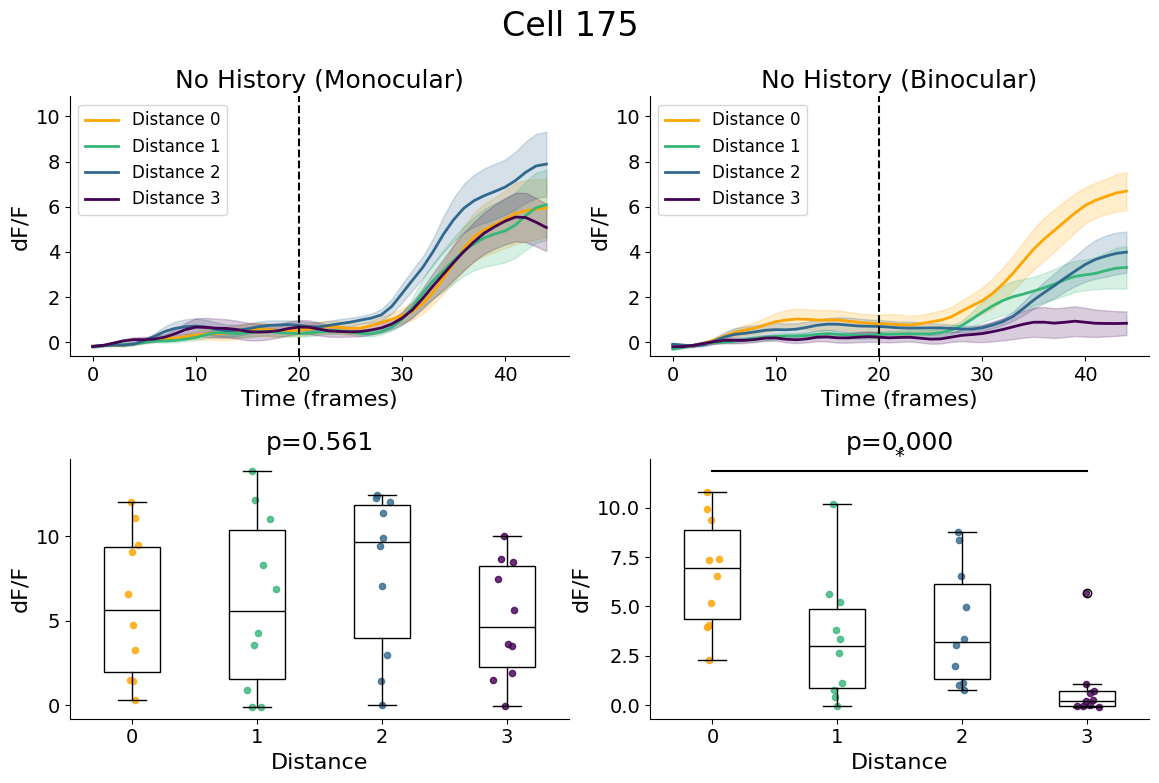

In [144]:
fig = plot_distance_and_rf_comparison(np.where(D.suite2p_id == cell_to_show)[0][0])

In [145]:
# for all reliable cells, plot the distance and rf comparison
fig_path = create_new_result_dir(results_path, r'distance_and_rf_comparison')
for cell in responsive_cells:
    fig = plot_distance_and_rf_comparison(cell)
    fig.savefig(os.path.join(fig_path, f'cell_{D.suite2p_id[cell]}_distance_and_rf_comparison.png'))
    plt.close(fig)

Creating directory: distance_and_rf_comparison


In [158]:
def get_significant_conditions(cell):
    """
    Determine which conditions show significant differences across distances for a given cell.
    
    Parameters:
    -----------
    cell : int
        The cell ID to analyze.
    
    Returns:
    --------
    dict : Dictionary
        Keys are condition names, values are tuples of (is_significant, p_value)
    """
    conditions = [
        {'history': False, 'monocular': True, 'name': 'No History (Monocular)'},
        {'history': False, 'monocular': False, 'name': 'No History (Binocular)'}
    ]
    
    distances = [0, 1, 2, 3]
    rf_index = find_receptive_field(cell)
    results = {}

    
    for condition in conditions:
        rf_values = []
        for distance in distances:
            traces, _ = get_all_traces(cell, whole_repeat='servo', 
                                     distance=distance,
                                     history=condition['history'],
                                     monocular=condition['monocular'])
            if traces.shape[1] > 25:
                traces = traces[:, 20:]
            rf_values.append(traces[:, rf_index])

        f_stat, p_value = f_oneway(*rf_values)
        results[condition['name']] = (p_value < 0.05, p_value)
        
    return results

In [182]:
results = get_significant_conditions(np.where(D.suite2p_id==18)[0][0])
results['No History (Monocular)']


(False, 0.262637176903135)

In [187]:
print(responsive_cells)
print(np.where(D.suite2p_id==responsive_cells[10])[0][0])

[0, 5, 8, 12, 13, 14, 17, 20, 21, 22, 24, 25, 31, 33, 34, 36, 38, 41, 42, 43, 44, 45, 47, 48, 50, 52, 54, 55, 56, 58, 59, 60, 61, 62, 64, 65, 66, 67, 68, 69, 71, 74, 77, 78, 79, 80, 81, 84, 86, 88, 89, 91, 96, 97, 99, 103, 104, 105, 110, 112, 113, 114, 116, 117, 118, 126, 127, 128, 130, 131, 134, 135, 136, 137, 140, 142, 146, 148, 149, 150, 151, 153, 154, 155, 159, 161, 162, 164, 165, 167, 170, 174, 175, 177, 178, 180, 181, 185, 186, 187, 189, 190, 193, 195, 199, 201, 202, 204, 206, 208, 209, 210, 214, 216, 217, 220, 222, 223, 224, 226, 227, 229, 230, 231, 234, 236, 237, 238, 240, 241, 242, 244, 246, 250, 251, 253, 254, 256, 257, 259, 260, 262, 266, 267, 269, 270, 271, 272, 273, 276, 279, 281, 282, 283, 286, 287, 288, 291, 292, 293, 298, 300, 301, 302, 304, 305, 308, 309, 310, 312, 313, 314, 315, 317, 321, 322, 323, 324, 326, 327, 329, 330, 333, 336, 337, 338, 339, 343, 345, 352, 360, 361, 364, 366, 371, 375, 376, 378, 381, 383, 384, 387, 388, 391, 393, 395, 398, 399, 400, 401, 404, 40

In [188]:
all_cell_data = []


# Assuming 'cell' is the index in the loop for responsive_cells
for cell, cell_id in enumerate(responsive_cells):
    results = get_significant_conditions(cell_id)
    
    # Extract monocular and binocular results
    is_sig_mono, p_val_mono = results['No History (Monocular)']
    is_sig_bino, p_val_bino = results['No History (Binocular)']
   
    cell_data = {
        "cellId": int(cell_id),  # Convert to Python int
        "cellName": f"Cell {np.where(D.suite2p_id==cell_id)[0]}",  # Add a name
        "significantCount": sum(1 for is_sig, _ in results.values() if bool(is_sig)),
        "is_monocular": bool(is_sig_mono),  # Convert numpy.bool_ to Python bool
        "is_binocular": bool(is_sig_bino),  # Convert numpy.bool_ to Python bool
        "p_value_monocular": float(p_val_mono),  # Convert numpy.float to Python float
        "p_value_binocular": float(p_val_bino)   # Convert numpy.float to Python float
    }
    
    all_cell_data.append(cell_data)

In [189]:
all_cell_data[np.where(D.suite2p_id==18)[0][0]]['is_monocular']
all_cell_data[np.where(D.suite2p_id==18)[0][0]]['p_value_monocular']

0.0001047097045584971

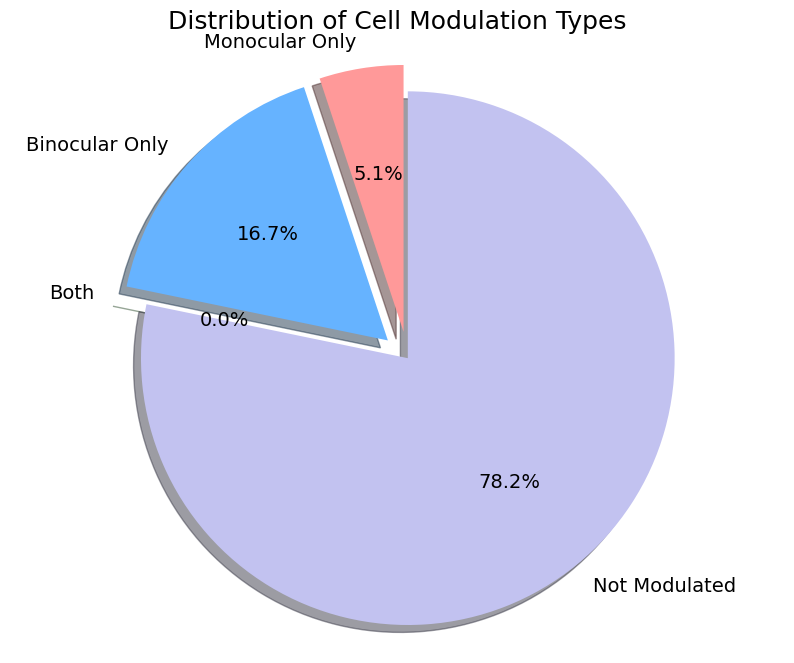

In [195]:
# Count cells with monocular and binocular modulation
monocular_modulated = 0
binocular_modulated = 0
both_modulated = 0
not_modulated = 0

for cell_data in all_cell_data:

    is_monocular =  cell_data['is_monocular']
    is_binocular = cell_data['is_binocular']
    
    if is_monocular and is_binocular:
        both_modulated += 1
    elif is_monocular:
        monocular_modulated += 1
    elif is_binocular:
        binocular_modulated += 1
    else:
        not_modulated += 1

# Create pie chart
labels = ['Monocular Only', 'Binocular Only', 'Both', 'Not Modulated']
sizes = [monocular_modulated, binocular_modulated, both_modulated, not_modulated]
colors = ['#ff9999', '#66b3ff', '#99ff99', '#c2c2f0']
explode = (0.1, 0.1, 0.1, 0)  # explode the first three slices

fig = plt.figure(figsize=(10, 8))
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%',
        shadow=True, startangle=90)
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle
plt.title('Distribution of Cell Modulation Types')

# Save the figure before showing it
plt.savefig(os.path.join(results_path, 'modulation_pie_chart.png'), bbox_inches='tight')
plt.show()
plt.close(fig)  # Close the specific figure object



In [191]:
# print in different directories the cells that are modulated by monocular and binocular
fig_path_monocular = create_new_result_dir(results_path, r'monocular_modulated')
fig_path_binocular = create_new_result_dir(results_path, r'binocular_modulated')

for cell_data in all_cell_data:
    if cell_data['is_monocular']:
        fig = plot_distance_and_rf_comparison(cell_data['cellId'])   
        fig.savefig(os.path.join(fig_path_monocular, f'cell_{cell_data['cellName']}_distance_and_rf_comparison.png'))
        plt.close(fig)
    if cell_data['is_binocular']:
        fig = plot_distance_and_rf_comparison(cell_data['cellId'])   
        fig.savefig(os.path.join(fig_path_binocular, f'cell_{cell_data['cellName']}_distance_and_rf_comparison.png'))
        plt.close(fig)


Creating directory: monocular_modulated
Creating directory: binocular_modulated


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

fig_path = create_new_result_dir(results_path, r'significant_conditions')

# Assuming you've already run your analysis and have results for all cells
def create_significance_heatmap(all_cell_data, output_file='significance_heatmap.png'):
    # Convert to a format suitable for heatmap
    conditions = ['No History (Monocular)', 'History (Monocular)', 
                  'No History (Binocular)', 'History (Binocular)']
    
    # Create DataFrame with p-values
    data = []
    cell_names = []  # Store cell names separately for index
    
    for cells in all_cell_data:
        # Get the cell name and properly format it
        cell_id = cells['cellName']
        print(cell_id)
        
        # Handle the case where cellName is a list like [13], also skip if it is []

        if isinstance(cell_id, list):
            cell_name = f"{cell_id[0]}"
        else:
            cell_name = f"{cell_id}"
           
            
        # Store the formatted name
        cell_names.append(cell_name)
        
        # Create row with p-values
        row = {}
        for cond in conditions:
            row[cond] = cells['conditions'][cond]['pValue']
        data.append(row)
    
    # Create DataFrame with explicit index using the cell names
    df = pd.DataFrame(data, index=cell_names)
    
    # Create the heatmap
    plt.figure(figsize=(10, 12))
    
    # Create a custom colormap - darker blue for more significant
    cmap = sns.color_palette("Blues_r", as_cmap=True)
    
    # Create the heatmap
    ax = sns.heatmap(df, cmap=cmap, 
                     vmin=0, vmax=0.15,
                     cbar_kws={'label': 'p-value'},
                     linewidths=0.5)
    
    # Highlight significant cells
    for i, cell_name in enumerate(df.index):
        for j, cond in enumerate(df.columns):
            pval = df.loc[cell_name, cond]
            if pval < 0.05:
                # Add asterisk for significant results
                ax.text(j + 0.5, i + 0.5, '*', 
                        ha='center', va='center', color='white', fontsize=12)
    
    plt.title('Cell Significance Across Conditions', fontsize=16)
    plt.tight_layout()
    plt.savefig(fig_path + r'\significant_conditions_heatmap.png', dpi=300, bbox_inches='tight')
    plt.close()
    
    print(f"Heatmap saved as {output_file}")
    

Directory significant_conditions already exists


Cell [13]
Cell [14]
Cell [17]
Cell [28]
Cell [36]
Cell [40]
Cell [41]
Cell [49]
Cell []
Cell [65]
Cell [69]
Cell [74]
Cell [84]
Cell [97]
Cell [98]
Cell [102]
Cell [103]
Cell [115]
Cell [120]
Cell [126]
Cell [129]
Cell [131]
Cell [134]
Cell [147]
Cell [149]
Cell [156]
Cell [158]
Cell [159]
Cell [161]
Cell [165]
Cell [173]
Cell [174]
Cell [175]
Cell [177]
Cell [179]
Cell [182]
Cell [183]
Cell [184]
Cell [185]
Cell []
Cell [190]
Cell [192]
Cell [193]
Cell [194]
Cell [195]
Cell [199]
Cell [201]
Cell [203]
Cell []
Cell []
Cell []
Cell []
Cell []
Cell [216]
Cell [217]
Cell []
Cell []
Cell []
Cell []
Cell [223]
Cell [225]
Cell []
Cell [227]
Cell [228]
Cell [232]
Cell []
Cell [233]
Cell []
Cell [235]
Cell []
Cell [236]
Cell [237]
Cell [238]
Cell [239]
Cell []


ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

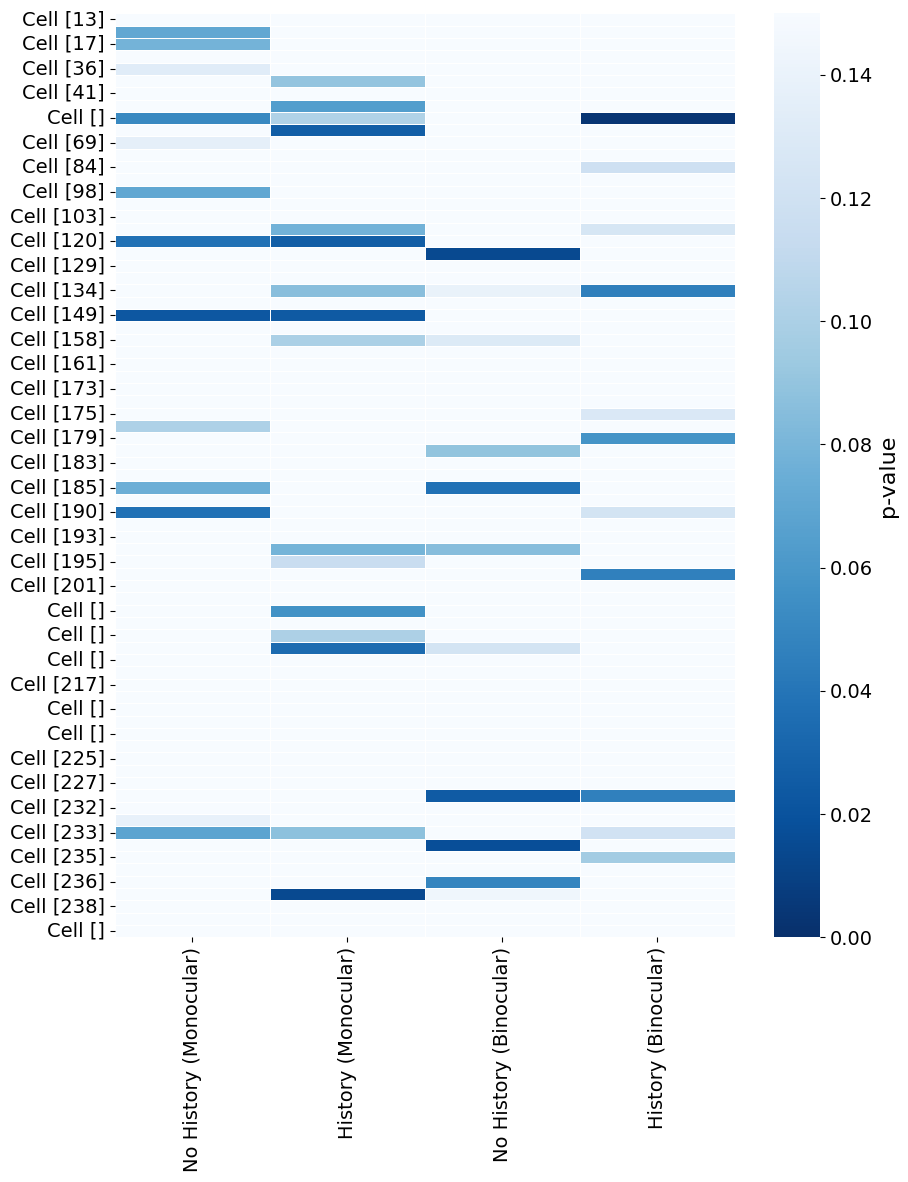

In [369]:
create_significance_heatmap(all_cell_data)

KeyError: 0

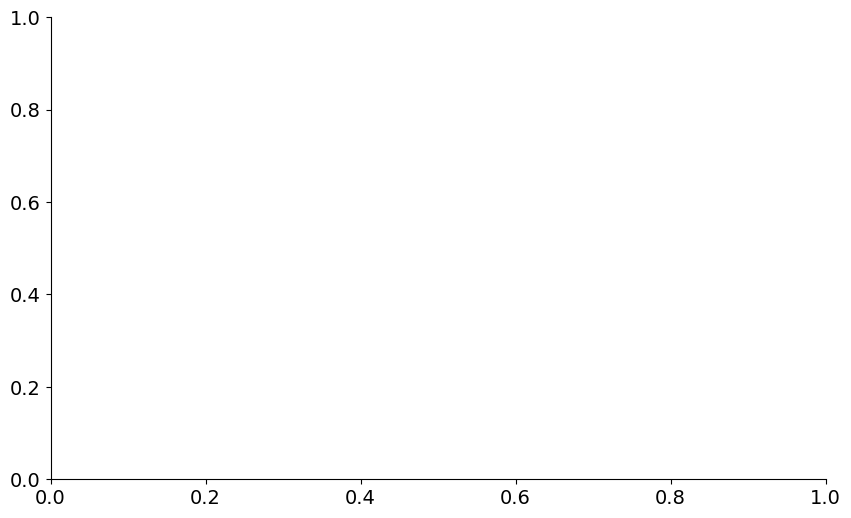

In [292]:
# do it for all responsive cells
significant_conditions = {}
for cell in responsive_cells:
    significant_conditions[D.suite2p_id[cell]] = get_significant_conditions(cell)

# make a bar plot of the significant conditions
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(significant_conditions.keys(), [significant_conditions[cell][0] for cell in significant_conditions.keys()])
ax.set_xticks(list(significant_conditions.keys()))
ax.set_xticklabels(list(significant_conditions.keys()), rotation=90)
ax.set_ylabel('Significant')
plt.show()


In [320]:
def plot_condition_comparison(cell, fig_path=None):
    """
    Creates a plot comparing one eye vs two eyes conditions with colorplots and mean responses.
    
    Parameters:
    -----------
    cell : int
        The cell ID to analyze.
    fig_path : str, optional
        Path to save the figure.
        
    Returns:
    --------
    fig : matplotlib.figure.Figure
        The figure object.
    """
    fig = plt.figure(figsize=(14, 8))
    gs = fig.add_gridspec(4, 2, height_ratios=[2, 2, 2, 3])
    axes = np.array([[fig.add_subplot(gs[i, j]) for j in range(2)] for i in range(4)])
    
    distances = [1, 2, 3]
    conditions = ['one eye', 'two eyes']
    distance_labels = ['Near', 'Medium', 'Far']
    condition_titles = ['One Eye', 'Two Eyes']

    all_data = get_all_traces(cell, block=None)
    vmin, vmax = np.percentile(all_data, [1, 99])
    
    for col, condition in enumerate(conditions):
        axes[0, col].set_title(condition_titles[col], fontsize=16)

        for row, distance in enumerate(distances):
            ax = axes[row, col]
            traces = get_all_traces(cell, distance=distance, block=condition)
            im = ax.pcolor(traces, cmap='viridis', vmin=vmin, vmax=vmax)
            
            ax.set_xticklabels([])
            ax.set_xticks([])
            ax.set_ylabel("Trial #")
            
            mean_trace = np.mean(traces, axis=0)
            axes[3, col].plot(mean_trace, label=distance_labels[row], color=colors[distance])
    
    for col in range(2):
        axes[3, col].set_xlabel("Time (frames)")
        axes[3, col].set_ylabel("Mean dF/F")
        axes[3, col].set_title("Mean Response by Distance")
        axes[3, col].legend()
        axes[3, col].set_ylim(vmin, vmax)
    
    cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
    fig.colorbar(im, cax=cbar_ax, label='dF/F')
    
    fig.suptitle(f'Cell {D.suite2p_id[cell]} Responses', fontsize=24)
    plt.tight_layout(rect=[0, 0, 0.9, 0.95])
    
    if fig_path is not None:
        plt.savefig(fig_path + '/cell_' + str(D.suite2p_id[cell]) + '_condition_comparison.png')
        plt.close()
        
    return fig

def plot_cell_distance_response(cell, figure_path=None):
    """
    Plot RF values by distance, comparing one eye vs two eyes conditions.
    
    Parameters:
    -----------
    cell : int
        Cell index to analyze
    figure_path : str, optional
        Path to save the figure.
    """
    if figure_path is None:
        figure_path = create_new_result_dir(results_path, r'block_response')
    
    distances = [1, 2, 3]
    fig, axes = plt.subplots(1, 2, figsize=(8,5))
    fig.suptitle(f'RF Values by Distance - Cell {D.suite2p_id[cell]}', fontsize=16)

    one_eye_data = [get_RF_value(cell=cell, distance=d, block='one eye') for d in distances]
    two_eyes_data = [get_RF_value(cell=cell, distance=d, block='two eyes') for d in distances]

    all_data = np.concatenate(one_eye_data + two_eyes_data)
    y_min, y_max = np.min(all_data), np.max(all_data)
    y_range = y_max - y_min
    y_lims = [y_min - 0.1*y_range, y_max + 0.2*y_range]

    for ax, data, title in zip(axes, [one_eye_data, two_eyes_data], ['One Eye Trials', 'Two Eyes Trials']):
        bp = ax.boxplot(data, patch_artist=True, showfliers=False)
        for patch in bp['boxes']:
            patch.set_facecolor('none')
            
        for i, values in enumerate(data):
            x_jitter = np.random.normal(0, 0.05, size=len(values))
            ax.scatter(np.ones_like(values) * (i+1) + x_jitter, values,
                      color=colors[i+1], alpha=0.7, s=40, label=f"{distances[i]:.1f}")
        
        ax.set_title(title)
        ax.set_ylabel('RF Value')
        ax.set_xlabel('Distance')
        ax.set_xticks(range(1, len(distances) + 1))
        ax.set_xticklabels([f"{d:.1f}" for d in distances])
        ax.set_ylim(y_lims)
        
        p_value = f_oneway(*data).pvalue
        y_bar = max([max(d) for d in data]) + 0.1 * y_range
        ax.plot([1, 1, len(distances), len(distances)], [y_bar, y_bar+0.05*y_range, y_bar+0.05*y_range, y_bar], lw=1.5, color='k')
        ax.text(len(distances)/2, y_bar + 0.05*y_range, '*' if p_value < 0.05 else 'n.s.', ha='center', va='bottom')

    plt.tight_layout()
    
    if figure_path:
        plt.savefig(figure_path + '/cell_' + str(D.suite2p_id[cell]) + '_boxplot.png')
    
    return fig, axes

In [385]:
def plot_distance_response(cell, fig_path=None):
    """
    Creates a simplified plot with only mean responses and RF value boxplots.
    
    Parameters:
    -----------
    cell : int
        The cell ID to analyze.
    fig_path : str, optional
        Path to save the figure.
        
    Returns:
    --------
    fig, axes : Figure and axes objects
    """
    fig = plt.figure(figsize=(14, 8))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])
    axes = np.array([[fig.add_subplot(gs[i, j]) for j in range(2)] for i in range(2)])
    
    distances = [1, 2, 3]
    conditions = ['one eye', 'two eyes']
    distance_labels = ['Near', 'Medium', 'Far']
    condition_titles = ['One Eye', 'Two Eyes']

    all_data = get_all_traces(cell, block=None)
    vmin, vmax = np.percentile(all_data, [1, 99])
    
    # Plot mean traces
    for col, condition in enumerate(conditions):
        axes[0, col].set_title(condition_titles[col], fontsize=16)
        
        for distance in distances:
            traces = get_all_traces(cell, distance=distance, block=condition)
            mean_trace = np.mean(traces, axis=0)
            axes[0, col].plot(mean_trace, label=distance_labels[distance-1], color=colors[distance], lw=2.5)
        # add title based on condition
        axes[0, col].set_title(condition_titles[col])
    
    for col in range(2):
        axes[0, col].set_xlabel("Time (frames)")
        axes[0, col].set_ylabel("Mean dF/F")
        axes[0, col].legend()
        axes[0, col].set_ylim(vmin, vmax)
    
    # Plot boxplots
    one_eye_data = [get_RF_value(cell=cell, distance=d, block='one eye') for d in distances]
    two_eyes_data = [get_RF_value(cell=cell, distance=d, block='two eyes') for d in distances]

    all_rf_data = np.concatenate(one_eye_data + two_eyes_data)
    y_min, y_max = np.min(all_rf_data), np.max(all_rf_data)
    y_range = y_max - y_min
    y_lims = [y_min - 0.1*y_range, y_max + 0.2*y_range]

    for col, (data, title) in enumerate(zip([one_eye_data, two_eyes_data], ['One Eye Trials', 'Two Eyes Trials'])):
        ax = axes[1, col]
        
        bp = ax.boxplot(data, patch_artist=True, showfliers=False)
        for patch in bp['boxes']:
            patch.set_facecolor('none')
            
        for i, values in enumerate(data):
            x_jitter = np.random.normal(0, 0.05, size=len(values))
            ax.scatter(np.ones_like(values) * (i+1) + x_jitter, values,
                      color=colors[i+1], alpha=0.7, s=40)
        
        ax.set_title(f"RF Values - {title}")
        ax.set_ylabel('RF Value')
        ax.set_xlabel('Distance')
        ax.set_xticks(range(1, len(distances) + 1))
        ax.set_xticklabels([f"{d:.1f}" for d in distances])
        ax.set_ylim(y_lims)
        
        p_value = f_oneway(*data).pvalue
        y_bar = max([max(d) for d in data]) + 0.1 * y_range
        ax.plot([1, 1, len(distances), len(distances)], [y_bar, y_bar+0.05*y_range, y_bar+0.05*y_range, y_bar], lw=1.5, color='k')
        ax.text(len(distances)/2, y_bar + 0.05*y_range, '*' if p_value < 0.05 else 'n.s.', ha='center', va='bottom')
    
    fig.suptitle(f'Cell {D.suite2p_id[cell]}', fontsize=24)
    plt.tight_layout()
    
    if fig_path is not None:
        plt.savefig(fig_path + '/cell_' + str(D.suite2p_id[cell]) + '.png')
        plt.close()
        
    return fig, axes

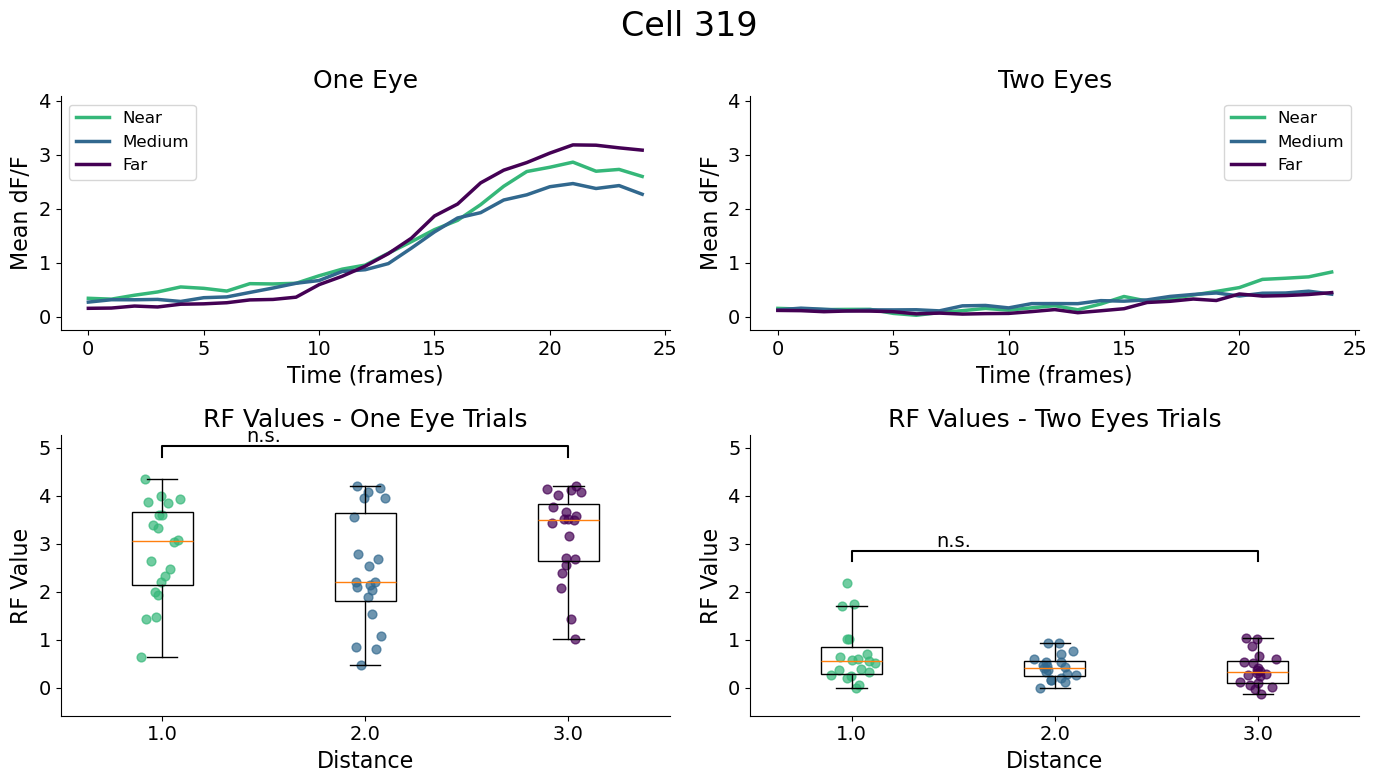

In [347]:
fig = plot_distance_response(315)

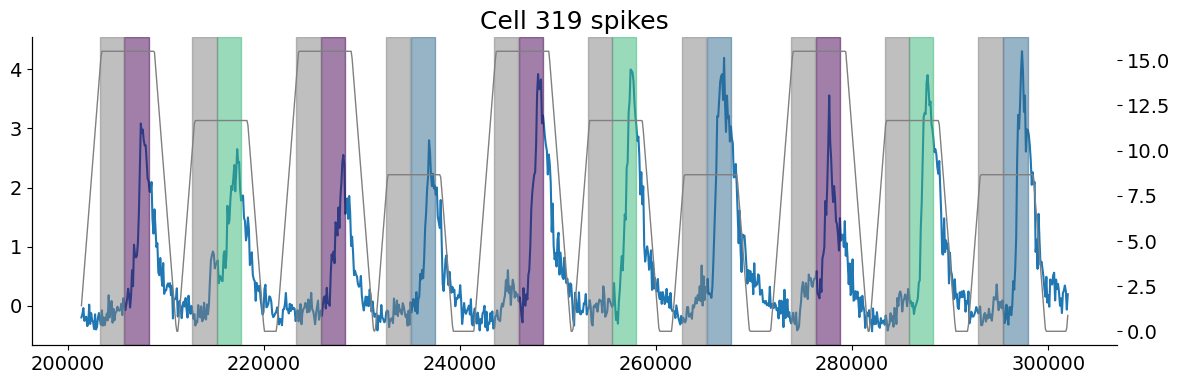

In [282]:
fig = plot_cell_stimulus_response(315, n_repeats=[20, 30])

First, see the cells that can be analyzed. I can set some metric as if they are significantly more active during on_times than during off_times

Found 355 responsive cells out of 563 total cells


C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_6268\1630518105.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, patch_artist=True, showfliers=False, labels=['ON', 'OFF'])


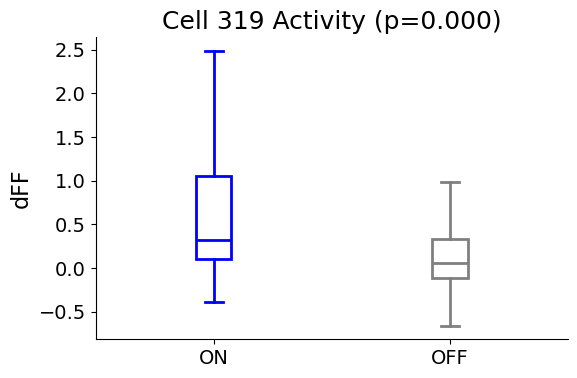

In [415]:
def is_cell_responsive(cell, plot=False):
    """
    Determines if a cell is significantly more active during on times than off times.
    
    Args:
        cell: Cell index to analyze
        plot: Whether to plot the boxplot of on vs off activity
        
    Returns:
        bool: True if cell is significantly more active during on times
    """
    # Use raw dFF data for the cell without z-scoring
    dff_data = D.dFF[cell]
    
    # Get on and off time activity directly from dFF
    on_activity = dff_data[on_time_interp]
    off_activity = dff_data[~on_time_interp]
    
    # Perform t-test
    _, p_value = ttest_ind(on_activity, off_activity)
    
    if plot:
        # Create boxplot
        fig, ax = plt.subplots(figsize=(6, 4))
        data = [on_activity, off_activity]
        bp = ax.boxplot(data, patch_artist=True, showfliers=False, labels=['ON', 'OFF'])
        
        # Customize boxplot colors and line thickness
        colors = ['blue', 'gray']
        for i, (box, whisker, cap, median) in enumerate(zip(bp['boxes'], bp['whiskers'][::2], bp['caps'][::2], bp['medians'])):
            box.set_facecolor('none')
            box.set_linewidth(2)
            box.set_edgecolor(colors[i])
            
            whisker.set_linewidth(2)
            whisker.set_color(colors[i])
            
            bp['whiskers'][i*2+1].set_linewidth(2)
            bp['whiskers'][i*2+1].set_color(colors[i])
            
            cap.set_linewidth(2)
            cap.set_color(colors[i])
            
            bp['caps'][i*2+1].set_linewidth(2)
            bp['caps'][i*2+1].set_color(colors[i])
            
            median.set_linewidth(2)
            median.set_color(colors[i])

        # add p-value annotation in the title
        ax.set_title(f'Cell {D.suite2p_id[cell]} Activity (p={p_value:.3f})')
    
        ax.set_ylabel('dFF')
        plt.tight_layout()
        
    # Check if mean on activity is greater and p-value significant
    return (np.mean(on_activity) > np.mean(off_activity)) and (p_value < 0.05)

responsive_cells = []
unresponsive_cells = []
for cell in range(D.dFF.shape[0]):
    is_responsive = is_cell_responsive(cell)
    if is_responsive:
        responsive_cells.append(cell)
    else:
        unresponsive_cells.append(cell)
     
print(f"Found {len(responsive_cells)} responsive cells out of {D.dFF.shape[0]} total cells")

# Example of plotting for a specific cell
if len(responsive_cells) > 0:
    is_cell_responsive(315, plot=True)

In [406]:
is_cell_responsive(315, plot=True)

TypeError: is_cell_responsive() got an unexpected keyword argument 'plot'

In [381]:
from scipy.stats import f_oneway

def plot_cell_distance_response(cell, fig_path=None):
    """
    Plot RF values by distance for a given cell, comparing one eye vs two eyes conditions.
    
    Parameters:
    -----------
    cell : int
        Cell index to analyze
    figure_path : str, optional
        Path to save the figure. If None, figure won't be saved.
    """
    if fig_path is None:
        fig_path = create_new_result_dir(results_path, r'block_response')
    
    distances = [1, 2, 3]

    # Set up figure
    fig, axes = plt.subplots(1, 2, figsize=(8,5))
    fig.suptitle(f'RF Values by Distance - Cell {D.suite2p_id[cell]}', fontsize=16)

    # Get data for both conditions
    one_eye_data = [get_RF_value(cell=cell, distance=d, block='one eye') for d in distances]
    two_eyes_data = [get_RF_value(cell=cell, distance=d, block='two eyes') for d in distances]

    # Set y-axis limits
    all_data = np.concatenate(one_eye_data + two_eyes_data)
    y_min, y_max = np.min(all_data), np.max(all_data)
    y_range = y_max - y_min
    y_lims = [y_min - 0.1*y_range, y_max + 0.2*y_range]

    # Plot both conditions
    for ax, data, title in zip(axes, [one_eye_data, two_eyes_data], ['One Eye', 'Two Eyes']):
        # Calculate p-value
        p_value = f_oneway(*data).pvalue
        
        # Create boxplot
        bp = ax.boxplot(data, patch_artist=True, showfliers=False)
        for patch in bp['boxes']:
            patch.set_facecolor('none')
            
        # Add scatter points with jitter
        for i, values in enumerate(data):
            x_jitter = np.random.normal(0, 0.05, size=len(values))
            ax.scatter(np.ones_like(values) * (i+1) + x_jitter, values,
                      color=colors[i+1], alpha=0.7, s=40, label=f"{distances[i]:.1f}")
        
        # Configure axis
        ax.set_title(f"{title} (p={p_value:.3f})", fontsize=14)
        ax.set_ylabel('RF Value')
        ax.set_xlabel('Distance')
        ax.set_xticks(range(1, len(distances) + 1))
        ax.set_xticklabels([f"{d:.1f}" for d in distances])
        ax.set_ylim(y_lims)
        
        # Add significance bar
        y_bar = max([max(d) for d in data]) + 0.1 * y_range
        ax.plot([1, 1, len(distances), len(distances)], [y_bar, y_bar+0.05*y_range, y_bar+0.05*y_range, y_bar], lw=1.5, color='k')
        ax.text(len(distances)/2, y_bar + 0.05*y_range, '*' if p_value < 0.05 else 'n.s.', ha='center', va='bottom')

    plt.tight_layout()
    
    if fig_path:
        plt.savefig(fig_path + '/cell_' + str(D.suite2p_id[cell]) + '_boxplot.png')
    
    return fig, axes

Directory block_response already exists


(<Figure size 800x500 with 2 Axes>,
 array([<Axes: title={'center': 'One Eye (p=0.107)'}, xlabel='Distance', ylabel='RF Value'>,
        <Axes: title={'center': 'Two Eyes (p=0.058)'}, xlabel='Distance', ylabel='RF Value'>],
       dtype=object))

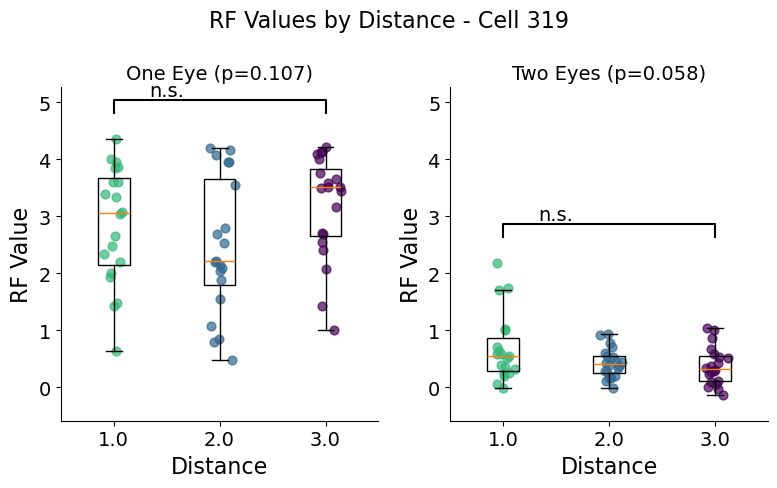

In [382]:
plot_cell_distance_response(315)

In [386]:
# Compute p-values for each cell and block
p_values = {}
monocular_modulated_path = create_new_result_dir(results_path, r'monocular_modulated_cells')
binocular_modulated_path = create_new_result_dir(results_path, r'binocular_modulated_cells')

for cell in responsive_cells:
    # Get cell ID
    p_values[cell] = {}
    
    # Get data for both conditions
    one_eye_data = [get_RF_value(cell=cell, distance=d, block='one eye') for d in [1, 2, 3]]
    two_eyes_data = [get_RF_value(cell=cell, distance=d, block='two eyes') for d in [1, 2, 3]]

    # if the RF_value mean is less than threshold, then cell can't be significant, but separetly for each condition
    threshold = 1   
    if np.mean(np.concatenate(one_eye_data).flatten()) < threshold:
        p_values[cell]['one_eye'] = 1
    else:
        p_values[cell]['one_eye'] = f_oneway(*one_eye_data).pvalue
    if np.mean(np.concatenate(two_eyes_data).flatten()) < threshold:
        p_values[cell]['two_eyes'] = 1
    else:
        p_values[cell]['two_eyes'] = f_oneway(*two_eyes_data).pvalue

    if p_values[cell]['one_eye'] < 0.05:
        fig = plot_distance_response(cell, fig_path=monocular_modulated_path)
    if p_values[cell]['two_eyes'] < 0.05:
        fig = plot_distance_response(cell, fig_path=binocular_modulated_path)

Creating directory: monocular_modulated_cells
Creating directory: binocular_modulated_cells


In [387]:
# sum cells with p-value < 0.05 for each condition
one_eye_count = sum(1 for cell_id in p_values if p_values[cell_id]['one_eye'] < 0.05)
two_eyes_count = sum(1 for cell_id in p_values if p_values[cell_id]['two_eyes'] < 0.05)

print(f"Number of cells with significant difference in one eye trials: {one_eye_count}")
print(f"Number of cells with significant difference in two eyes trials: {two_eyes_count}")

Number of cells with significant difference in one eye trials: 6
Number of cells with significant difference in two eyes trials: 24


Number of responsive cells: 355
Number of unresponsive cells: 208


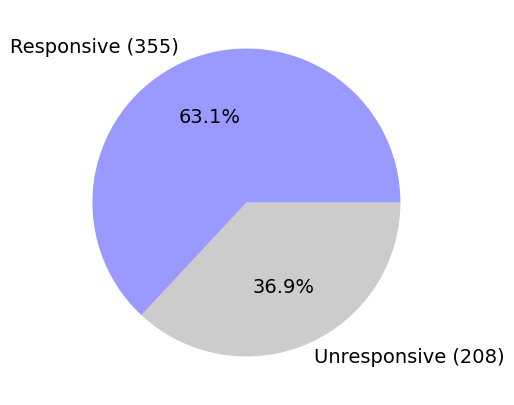

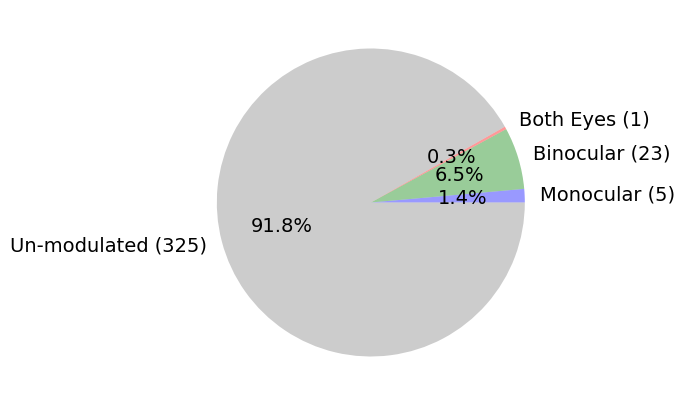

In [405]:
# count responsive cells and unresponsive cells 
n_responsive_cells = len(responsive_cells)
n_unresponsive_cells = len(unresponsive_cells)

print(f"Number of responsive cells: {n_responsive_cells}")
print(f"Number of unresponsive cells: {n_unresponsive_cells}")

# do a pie plot of responsive vs unresponsive cells
plt.figure(figsize=(5,5))
plt.pie([n_responsive_cells, n_unresponsive_cells], 
        labels=[f'Responsive ({n_responsive_cells})', f'Unresponsive ({n_unresponsive_cells})'], 
        autopct='%1.1f%%',
        colors=['blue', 'gray'])
# Set transparency with a separate call
plt.gca().patches[0].set_alpha(0.4)
plt.gca().patches[1].set_alpha(0.4)
plt.show()

# do another one with, within the responsive, the ones monocular, binocular and both
monocular_cells = [cell for cell in responsive_cells[:-1] if p_values[cell]['one_eye'] < 0.05 and p_values[cell]['two_eyes'] > 0.05]
binocular_cells = [cell for cell in responsive_cells[:-1] if p_values[cell]['one_eye'] > 0.05 and p_values[cell]['two_eyes'] < 0.05]
both_eyes_cells = [cell for cell in responsive_cells[:-1] if p_values[cell]['one_eye'] < 0.05 and p_values[cell]['two_eyes'] < 0.05]
un_modulated = [cell for cell in responsive_cells[:-1] if p_values[cell]['one_eye'] > 0.05 and p_values[cell]['two_eyes'] > 0.05]

# do the pie plot again, but now within the responsive cells
plt.figure(figsize=(5,5))
plt.pie([len(monocular_cells), len(binocular_cells), len(both_eyes_cells), len(un_modulated)], 
        labels=[f'Monocular ({len(monocular_cells)})', f'Binocular ({len(binocular_cells)})', 
                f'Both Eyes ({len(both_eyes_cells)})', f'Un-modulated ({len(un_modulated)})'], 
        autopct='%1.1f%%',
        colors=['blue', 'green', 'red', 'gray'])
# Set transparency with a separate call
for i in range(len(plt.gca().patches)):
    plt.gca().patches[i].set_alpha(0.4)
plt.show()



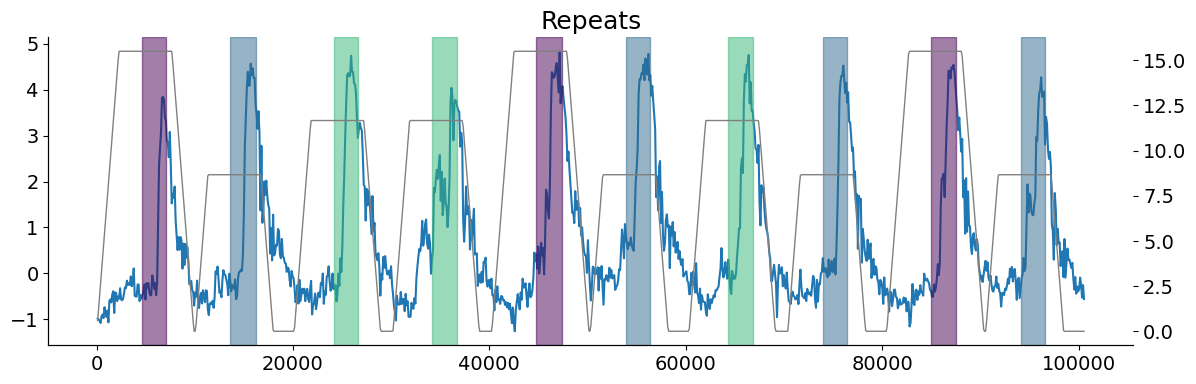

In [63]:
plt.figure(figsize=(14,4))
plt.title('Repeats')

repeats = np.arange(10)

repeat_start = trial_start_time[repeats[0]]*1000
repeat_end = trial_end_time[repeats[-1]]*1000

repeats_frames = (frames_time > repeat_start) & (frames_time < repeat_end)

ax = plt.gca()
ax1 = ax.twinx()
ax.plot(frames_time[repeats_frames], D.dFF[id, repeats_frames].T)
ax1.plot(frames_time[repeats_frames], stepper_pos_interp[repeats_frames]/30, lw=1, color='gray')

for rep in repeats:
    trial_start, trial_end = get_on_times(rep)
    plt.axvspan(trial_start, trial_end, color=colors[trial_sequence[rep]], alpha=0.5)


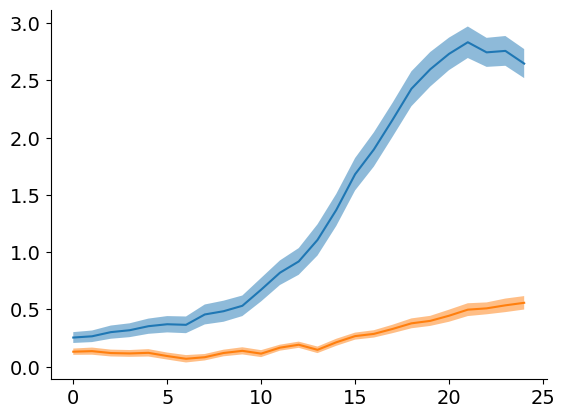

(60, 25)
(59, 25)


In [74]:
cell = 319
id = find_suite2p_cell(cell)

traces_all_mean, traces_all_sem = get_all_traces(id, mean_trace=True)
traces_one_mean, traces_one_sem = get_all_traces(id, mean_trace=True, block='one eye')
traces_two_mean, traces_two_sem = get_all_traces(id, mean_trace=True, block='two eyes')

plt.figure()
plt.plot(traces_one_mean.T)
# add sem as error bars
plt.fill_between(np.arange(len(traces_one_mean)), traces_one_mean - traces_one_sem, traces_one_mean + traces_one_sem, alpha=0.5)
plt.plot(traces_two_mean.T)
# add sem as error bars
plt.fill_between(np.arange(len(traces_two_mean)), traces_two_mean - traces_two_sem, traces_two_mean + traces_two_sem, alpha=0.5)
plt.show()

# find where is the max of traces_all_mean
max_all = np.argmax(traces_all_mean)



all_traces_one_distance = get_all_traces(id, block='one eye')




In [80]:
receptive_field_values = get_RF_value(id, block='one eye')

print(receptive_field_values)




[1.6758354, 0.13057587]
